# POSEIDON: Dual Pipeline IUU Fishing Detection System (WPPNRI 711 - Data 2026)

Pipeline deteksi penangkapan ikan ilegal (*Illegal, Unreported, and Unregulated/IUU Fishing*) di Wilayah Pengelolaan Perikanan Negara Republik Indonesia (WPPNRI 711 - Laut Natuna Utara).

Struktur tahapan (Lanjutan):
1. **Phase 4: Dual Pipeline PU Learning (nnPU) - GFW (old) & GEE (new-mitigasi), Conformal Prediction, Out-of-Time Scoring (2025 & 2026), Sistem Siaga Temporal Kuartal, serta Ekspor Hasil**

In [1]:
!pip install pandas numpy matplotlib seaborn tqdm pyarrow gdown geopandas shapely lightgbm xgboost scikit-learn scipy requests earthengine-api pyogrio -q

## Konfigurasi Global, Download Data & Import Library

In [2]:
import os
import glob
import time
import json
import zipfile
import joblib
import warnings
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPolygon
from shapely.vectorized import contains as shapely_contains
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.stats import ks_2samp, chi2_contingency, mannwhitneyu
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
import gdown

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

PALETTE = {
    'old': '#E74C3C',
    'new': '#27AE60',
    'p': '#E74C3C',
    'u': '#95A5A6',
    'rn': '#2E86C1',
    'dark': '#34495E',
    'ais': '#16A085',
    'accent': '#F39C12',
    'purple': '#8E44AD'
}

In [3]:
import gdown

FULL_LABELED_ID = "1Iv17WnmBxXndpcsrWDbjmZDB7oV98E_T"
FULL_LABELED_PATH = "POSEIDON_Full_Labeled.csv"

if not os.path.exists(FULL_LABELED_PATH):
    gdown.download(id=FULL_LABELED_ID, output=FULL_LABELED_PATH, quiet=False)

sar_labeled_full = pd.read_csv(FULL_LABELED_PATH, low_memory=False)
sar_labeled_full['timestamp'] = pd.to_datetime(sar_labeled_full['timestamp'], utc=True)
sar_labeled_full['year'] = sar_labeled_full['timestamp'].dt.year

print(f"Total baris termuat: {len(sar_labeled_full):,}")
print(f"Rentang tahun: {sar_labeled_full['year'].min()} - {sar_labeled_full['year'].max()}")

sar_labeled = sar_labeled_full.copy()
sar_labeled_new = sar_labeled_full.copy()

df_2026_clean = sar_labeled_full[sar_labeled_full['year'] == 2026].copy()
sar_labeled_2026 = df_2026_clean.copy()
print(f"Data 2026 (subset): {len(df_2026_clean):,} baris")

Total baris termuat: 184,248
Rentang tahun: 2023 - 2026
Data 2026 (subset): 32,397 baris


In [4]:
print(" DISTRIBUSI LABEL PER TAHUN \n")
distribusi_tahun = sar_labeled_full.groupby('year')['label'].value_counts().unstack(fill_value=0)
distribusi_tahun = distribusi_tahun.reindex(columns=['P', 'RN', 'U'], fill_value=0)
distribusi_tahun['Total'] = distribusi_tahun.sum(axis=1)
print(distribusi_tahun)

print("\n DISTRIBUSI LABEL AKUMULASI TOTAL (2023-2026 s.d. Juni) \n")
distribusi_total = sar_labeled_full['label'].value_counts().reindex(['P', 'RN', 'U'], fill_value=0)
distribusi_total['Total'] = distribusi_total.sum()
print(distribusi_total)

 DISTRIBUSI LABEL PER TAHUN 

label   P    RN      U  Total
year                         
2023   24  8102  43965  52091
2024    9  7409  40226  47644
2025    3  7923  44190  52116
2026    8  4106  28283  32397

 DISTRIBUSI LABEL AKUMULASI TOTAL (2023-2026 s.d. Juni) 

label
P            44
RN        27540
U        156664
Total    184248
Name: count, dtype: int64


# Phase 4 - STEP 1: PU Learning dengan Hybrid Stacking Ensemble

Implementasi Non-negative PU (nnPU) Loss (Kiryo et al., 2017) sebagai fungsi objektif untuk LightGBM dan XGBoost.

In [5]:
def make_nnpu_objective(pi, beta=0.0, gamma=1.0, eps=1e-7):
    def nnpu_objective(preds, train_data):
        y = train_data.get_label()
        p = 1.0 / (1.0 + np.exp(-preds))
        p = np.clip(p, eps, 1 - eps)

        is_p = (y == 1)
        is_u = (y == 0)
        n_p_b = is_p.sum()
        n_u_b = is_u.sum()
        grad = np.zeros_like(preds)
        hess = np.zeros_like(preds)

        if n_p_b == 0 or n_u_b == 0:
            return grad, hess

        N_b = n_p_b + n_u_b
        w_p = pi * N_b / n_p_b
        w_u = 1.0 * N_b / n_u_b

        Rp_minus = np.mean(-np.log(1 - p[is_p]))
        Ru_minus = np.mean(-np.log(1 - p[is_u]))
        correction = Ru_minus - pi * Rp_minus

        grad[is_p] += w_p * (p[is_p] - 1.0)
        hess[is_p] += w_p * (p[is_p] * (1 - p[is_p]))

        if correction > beta:
            grad[is_u] += w_u * p[is_u]
            hess[is_u] += w_u * (p[is_u] * (1 - p[is_u]))
            grad[is_p] += -w_p * p[is_p]
            hess[is_p] += w_p * (p[is_p] * (1 - p[is_p]))
        else:
            grad[is_u] += -gamma * w_u * p[is_u]
            hess[is_u] += gamma * w_u * (p[is_u] * (1 - p[is_u]))
            grad[is_p] += gamma * w_p * p[is_p]
            hess[is_p] += gamma * w_p * (p[is_p] * (1 - p[is_p]))

        return grad, hess
    return nnpu_objective


def make_nnpu_eval(pi):
    def nnpu_eval_metric(preds, train_data):
        y = train_data.get_label()
        p = 1.0 / (1.0 + np.exp(-preds))
        p = np.clip(p, 1e-7, 1 - 1e-7)
        is_p = (y == 1)
        is_u = (y == 0)
        if is_p.sum() == 0 or is_u.sum() == 0:
            return 'nnpu_risk', 0.0, False
        Rp_plus = np.mean(-np.log(p[is_p]))
        Rp_minus = np.mean(-np.log(1 - p[is_p]))
        Ru_minus = np.mean(-np.log(1 - p[is_u]))
        risk = pi * Rp_plus + max(0.0, Ru_minus - pi * Rp_minus)
        return 'nnpu_risk', risk, False
    return nnpu_eval_metric


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def compute_metrics(y_true, y_score, label=""):
    auc = roc_auc_score(y_true, y_score)
    auprc = average_precision_score(y_true, y_score)
    order = np.argsort(-y_score)
    n_p_tot = y_true.sum()
    results = {'label': label, 'auc_roc': round(auc, 6), 'auprc': round(auprc, 8), 'n_positif': int(n_p_tot)}
    for K in [20, 50, 100, 500, 1000, 5000]:
        hit = y_true[order[:K]].sum()
        prec = hit / K
        rec = hit / n_p_tot if n_p_tot > 0 else 0.0
        lift = prec / y_true.mean() if y_true.mean() > 0 else 0.0
        results[f'p@{K}'] = round(prec, 5)
        results[f'r@{K}'] = round(rec, 3)
        results[f'lift@{K}'] = round(lift, 1)
        results[f'hit@{K}'] = int(hit)
    rank_of_p = np.where(y_true[order] == 1)[0] + 1
    results['p_in_top1pct'] = int((rank_of_p <= len(y_true) * 0.01).sum()) if len(rank_of_p) > 0 else 0
    return results


def compute_alert_efficiency(df_ref, score_array, pass_date_col='pass_date', pu_col='pu_flag', label_col='label', pos_label='P', top_n=10):
    tmp = pd.DataFrame({pass_date_col: df_ref[pass_date_col].values})
    if pu_col in df_ref.columns:
        tmp['__flag__'] = df_ref[pu_col].values.astype(float)
    elif label_col in df_ref.columns:
        tmp['__flag__'] = (df_ref[label_col].values == pos_label).astype(float)
    else:
        raise ValueError(f"Tidak ditemukan kolom '{pu_col}' maupun '{label_col}' untuk menghitung alert efficiency")
    tmp['__score__'] = np.asarray(score_array)

    hits, total = 0.0, 0.0
    for _, grp in tmp.groupby(pass_date_col):
        top_grp = grp.sort_values('__score__', ascending=False).head(top_n)
        total += grp['__flag__'].sum()
        hits += top_grp['__flag__'].sum()

    hits, total = int(hits), int(total)
    pct = round(hits / total * 100.0, 2) if total > 0 else 0.0
    pct_display = f"{pct:.1f}".replace('.', ',') + '%'

    return {
        'alert_efficiency_hits': hits,
        'alert_efficiency_total': total,
        'alert_efficiency': pct,
        'alert_efficiency_ratio': f"{hits}/{total}",
        'alert_efficiency_display': pct_display
    }


def select_best_model(df_compare, margin=0.05):
    df_sorted = df_compare.sort_values('auprc', ascending=False).reset_index(drop=True)
    top_auprc = df_sorted.iloc[0]['auprc']
    candidates = df_sorted[df_sorted['auprc'] >= top_auprc * (1 - margin)]
    if len(candidates) == 1:
        return candidates.iloc[0]['label'], candidates.iloc[0]
    best_row = candidates.sort_values('alert_efficiency', ascending=False).iloc[0]
    return best_row['label'], best_row

print("Fungsi nnPU loss, eval metric, sigmoid, compute_metrics, dan compute_alert_efficiency siap.")

Fungsi nnPU loss, eval metric, sigmoid, compute_metrics, dan compute_alert_efficiency siap.


## STEP 1A: PU Learning (Pipeline GFW - Fitur Baseline)

In [6]:
sar_labeled_full['radar_intensity_diff'] = (sar_labeled_full['vv_intensity_db'] - sar_labeled_full['vh_intensity_db']).astype(np.float32)
sar_labeled_full['is_dark'] = (1 - sar_labeled_full['ais_matched']).astype(int)
sar_labeled_full['quarter'] = pd.to_datetime(sar_labeled_full['timestamp']).dt.quarter

FEATURE_COLS_OLD = [
    'vv_intensity_db', 'vh_intensity_db', 'radar_intensity_diff', 'background_clutter', 'snr_db',
    'length_m', 'dist_to_nearest_mpa_km', 'dist_to_eez_boundary_km', 'dist_to_nearest_port_km',
    'dist_to_nearest_seizure_km', 'matching_score', 'ais_flag_country_encoded', 'fishing_score',
    'area_dark_count_30d', 'area_dark_flag', 'historical_hotspot', 'quarter'
]
FEATURE_COLS_OLD = [c for c in FEATURE_COLS_OLD if c in sar_labeled_full.columns]
CATEGORICAL_FEATURES = ['quarter']

MONO_MAP = {
    'fishing_score': 1, 'dist_to_nearest_seizure_km': -1,
    'area_dark_count_30d': 1, 'historical_hotspot': 1, 'area_dark_flag': 1,
}
mono_constraints_old = [MONO_MAP.get(c, 0) for c in FEATURE_COLS_OLD]
print(f"FEATURE_COLS ({len(FEATURE_COLS_OLD)}): {FEATURE_COLS_OLD}")

train_mask = sar_labeled_full['year'] <= 2025
test_mask = (sar_labeled_full['year'] == 2026) & (pd.to_datetime(sar_labeled_full['timestamp']).dt.month <= 6)

df_train_full = sar_labeled_full[train_mask].copy()
df_test_full = sar_labeled_full[test_mask].copy()

df_p_train = df_train_full[df_train_full['label'] == 'P'].copy()
df_u_train = df_train_full[df_train_full['label'] == 'U'].copy()
df_rn_train = df_train_full[df_train_full['label'] == 'RN'].copy()

print(f"Train (2023-2025): P={len(df_p_train)}, U={len(df_u_train)}, RN={len(df_rn_train)}")
print(f"Test/OOT (2026)  : P={(df_test_full['label']=='P').sum()}, U={(df_test_full['label']=='U').sum()}, RN={(df_test_full['label']=='RN').sum()}")

n_p, n_rn = len(df_p_train), len(df_rn_train)
pi_point = float(n_p / (n_p + n_rn))
print(f"pi_point: {pi_point:.5f}")

N_BOOTSTRAP = 2000
rng_pi = np.random.RandomState(42)
boot_pis = []
for _ in range(N_BOOTSTRAP):
    p_idx = rng_pi.choice(df_p_train.index, size=n_p, replace=True)
    rn_idx = rng_pi.choice(df_rn_train.index, size=n_rn, replace=True)
    boot_pis.append(len(np.unique(p_idx)) / (len(np.unique(p_idx)) + len(np.unique(rn_idx))))

pi_low, pi_high = np.percentile(boot_pis, [2.5, 97.5])
PI_ENSEMBLE = [pi_low, pi_point, pi_high]
print(f"PI_ENSEMBLE: {PI_ENSEMBLE}")

FEATURE_COLS (17): ['vv_intensity_db', 'vh_intensity_db', 'radar_intensity_diff', 'background_clutter', 'snr_db', 'length_m', 'dist_to_nearest_mpa_km', 'dist_to_eez_boundary_km', 'dist_to_nearest_port_km', 'dist_to_nearest_seizure_km', 'matching_score', 'ais_flag_country_encoded', 'fishing_score', 'area_dark_count_30d', 'area_dark_flag', 'historical_hotspot', 'quarter']
Train (2023-2025): P=36, U=128381, RN=23434
Test/OOT (2026)  : P=8, U=22935, RN=4106
pi_point: 0.00153
PI_ENSEMBLE: [np.float64(0.0012836905440329592), 0.001533873029399233, np.float64(0.001815251135152168)]


### Pelatihan Model Komponen & Hybrid Ensemble (Pipeline GFW)

In [7]:
train_df = pd.concat([df_p_train, df_u_train], axis=0).reset_index(drop=True)
train_df['pu_flag'] = np.where(train_df['label'] == 'P', 1.0, 0.0)

test_df = df_test_full.copy()
test_df['pu_flag'] = np.where(test_df['label'] == 'P', 1.0, 0.0)

X_train = train_df[FEATURE_COLS_OLD].astype(np.float32)
y_train = train_df['pu_flag'].values.astype(np.float32)

X_test = test_df[FEATURE_COLS_OLD].astype(np.float32)
y_test = test_df['pu_flag'].values.astype(np.float32)

print(f"Train: {len(X_train)} baris | Test (OOT 2026): {len(X_test)} baris, P={int(y_test.sum())}")

LGB_PARAMS = {
    'num_leaves': 15, 'max_depth': 4, 'min_child_samples': 10, 'learning_rate': 0.05,
    'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 5,
    'lambda_l1': 0.0, 'lambda_l2': 1.0, 'min_gain_to_split': 0.0,
    'verbosity': -1, 'deterministic': True, 'force_row_wise': True,
}
XGB_PARAMS = {
    'max_depth': 4, 'eta': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8,
    'lambda': 1.0, 'min_child_weight': 1.0, 'base_score': 0.0, 'verbosity': 0, 'nthread': 1,
}
SEEDS = [42, 123, 999, 7, 2024]
N_ROUNDS = 200
W_LGB = 0.5

pred_lgb_pi = {pi_val: np.zeros(len(X_test), dtype=np.float64) for pi_val in PI_ENSEMBLE}
pred_xgb_pi = {pi_val: np.zeros(len(X_test), dtype=np.float64) for pi_val in PI_ENSEMBLE}

dm_test = xgb.DMatrix(X_test)
final_models_lgb, final_models_xgb = [], []

for seed in SEEDS:
    dtrain = lgb.Dataset(X_train, label=y_train, categorical_feature=CATEGORICAL_FEATURES)
    dm_train = xgb.DMatrix(X_train, label=y_train)

    for pi_val in PI_ENSEMBLE:
        fold_params = LGB_PARAMS.copy()
        fold_params['seed'] = seed
        fold_params['monotone_constraints'] = mono_constraints_old
        fold_params['objective'] = make_nnpu_objective(pi_val)
        model_lgb = lgb.train(params=fold_params, train_set=dtrain, num_boost_round=N_ROUNDS)
        pred_lgb_pi[pi_val] += _sigmoid(model_lgb.predict(X_test, raw_score=True)) / len(SEEDS)
        final_models_lgb.append(model_lgb)

        xgb_params = XGB_PARAMS.copy()
        xgb_params['seed'] = seed
        booster = xgb.train(params=xgb_params, dtrain=dm_train, num_boost_round=N_ROUNDS,
                             obj=make_nnpu_objective(pi_val))
        pred_xgb_pi[pi_val] += _sigmoid(booster.predict(dm_test, output_margin=True)) / len(SEEDS)
        final_models_xgb.append(booster)

    print(f"Seed {seed} selesai.")

pred_lgb_old = np.mean([pred_lgb_pi[pi_val] for pi_val in PI_ENSEMBLE], axis=0)
pred_xgb_old = np.mean([pred_xgb_pi[pi_val] for pi_val in PI_ENSEMBLE], axis=0)
pred_ens_old = W_LGB * pred_lgb_old + (1 - W_LGB) * pred_xgb_old

metrics_lgb_old = compute_metrics(y_test, pred_lgb_old, "LightGBM (Old)")
metrics_xgb_old = compute_metrics(y_test, pred_xgb_old, "XGBoost (Old)")
metrics_ens_old = compute_metrics(y_test, pred_ens_old, "Hybrid Stacking (Old)")

print("\nEvaluasi OOT 2026 (Pipeline GFW):")
print(f"  LightGBM  : AUC={metrics_lgb_old['auc_roc']:.4f}, AUPRC={metrics_lgb_old['auprc']:.6f}")
print(f"  XGBoost   : AUC={metrics_xgb_old['auc_roc']:.4f}, AUPRC={metrics_xgb_old['auprc']:.6f}")
print(f"  Stacking  : AUC={metrics_ens_old['auc_roc']:.4f}, AUPRC={metrics_ens_old['auprc']:.6f}")

Train: 128417 baris | Test (OOT 2026): 27049 baris, P=8
Seed 42 selesai.
Seed 123 selesai.
Seed 999 selesai.
Seed 7 selesai.
Seed 2024 selesai.

Evaluasi OOT 2026 (Pipeline GFW):
  LightGBM  : AUC=0.9495, AUPRC=0.005229
  XGBoost   : AUC=0.9424, AUPRC=0.005107
  Stacking  : AUC=0.9465, AUPRC=0.005115


### Fungsi Skoring & Evaluasi Pemisahan P / RN (Pipeline GFW)

In [8]:
def poseidon_score_old(df_in):
    Xf = df_in[FEATURE_COLS_OLD].astype(np.float32)
    p_lgb = np.mean([_sigmoid(m.predict(Xf, raw_score=True)) for m in final_models_lgb], axis=0)
    dm = xgb.DMatrix(Xf)
    p_xgb = np.mean([_sigmoid(b.predict(dm, output_margin=True)) for b in final_models_xgb], axis=0)
    return W_LGB * p_lgb + (1 - W_LGB) * p_xgb

def poseidon_score_lgb_old(df_in):
    Xf = df_in[FEATURE_COLS_OLD].astype(np.float32)
    return np.mean([_sigmoid(m.predict(Xf, raw_score=True)) for m in final_models_lgb], axis=0)

def poseidon_score_xgb_old(df_in):
    Xf = df_in[FEATURE_COLS_OLD].astype(np.float32)
    dm = xgb.DMatrix(Xf)
    return np.mean([_sigmoid(b.predict(dm, output_margin=True)) for b in final_models_xgb], axis=0)

df_rn_eval = df_rn_train.copy()
df_rn_eval['risk_score'] = poseidon_score_old(df_rn_eval)
df_p_eval = df_p_train.copy()
df_p_eval['risk_score'] = poseidon_score_old(df_p_eval)
print(f"Rata-rata Skor P  (Pipeline GFW): {df_p_eval['risk_score'].mean():.4f}")
print(f"Rata-rata Skor RN (Pipeline GFW): {df_rn_eval['risk_score'].mean():.4f}")

Rata-rata Skor P  (Pipeline GFW): 0.4845
Rata-rata Skor RN (Pipeline GFW): 0.0002


### Feature Importance Gain (Pipeline GFW)

In [9]:
imp_old = pd.DataFrame({
    'feature': final_models_lgb[0].feature_name(),
    'gain': np.mean([m.feature_importance(importance_type='gain') for m in final_models_lgb], axis=0),
}).sort_values('gain', ascending=False)
imp_old['gain_pct'] = 100 * imp_old['gain'] / imp_old['gain'].sum()
print("Top Feature Importance (Pipeline GFW):")
print(imp_old.head(10).to_string(index=False))

Top Feature Importance (Pipeline GFW):
                   feature        gain  gain_pct
                  length_m 5793.476067 20.029502
dist_to_nearest_seizure_km 4390.614033 15.179456
      radar_intensity_diff 2413.480740  8.344009
             fishing_score 2372.545115  8.202484
   dist_to_eez_boundary_km 2238.615259  7.739455
           vv_intensity_db 1913.240499  6.614553
    dist_to_nearest_mpa_km 1818.727758  6.287799
           vh_intensity_db 1619.033877  5.597407
                    snr_db 1575.560892  5.447110
   dist_to_nearest_port_km 1499.882682  5.185471


### Bootstrap 95% Confidence Interval & Evaluasi Metrik (Pipeline GFW)

In [10]:
test_df['pass_date'] = pd.to_datetime(test_df['timestamp']).dt.date

pred_map_old = {
    'LightGBM (Old)': pred_lgb_old,
    'XGBoost (Old)': pred_xgb_old,
    'Hybrid Stacking (Old)': pred_ens_old
}

for _label, _pred in pred_map_old.items():
    _ae = compute_alert_efficiency(test_df, _pred, pass_date_col='pass_date', pu_col='pu_flag', top_n=10)
    if _label == 'LightGBM (Old)':
        metrics_lgb_old.update(_ae)
    elif _label == 'XGBoost (Old)':
        metrics_xgb_old.update(_ae)
    else:
        metrics_ens_old.update(_ae)

df_compare_old = pd.DataFrame([metrics_lgb_old, metrics_xgb_old, metrics_ens_old])

print("TABEL PERBANDINGAN MODEL OOT (Pipeline GFW):")
print(df_compare_old[['label', 'auc_roc', 'auprc']].to_string(index=False))

best_old_row = df_compare_old.loc[df_compare_old['auprc'].idxmax()]
best_old_name = best_old_row['label']

print(f"\nModel Terbaik (Pipeline GFW, OOT — kriteria AUPRC tertinggi): {best_old_name}")
print(f"  AUC-ROC          : {best_old_row['auc_roc']:.4f}")
print(f"  AUPRC            : {best_old_row['auprc']:.6f}")
print(f"  Alert Efficiency : {best_old_row['alert_efficiency_ratio']} = {best_old_row['alert_efficiency']:.1f}%")

pred_map = pred_map_old
test_df['pred_score'] = pred_map[best_old_name]

TABEL PERBANDINGAN MODEL OOT (Pipeline GFW):
                label  auc_roc    auprc
       LightGBM (Old) 0.949489 0.005229
        XGBoost (Old) 0.942435 0.005107
Hybrid Stacking (Old) 0.946512 0.005115

Model Terbaik (Pipeline GFW, OOT — kriteria AUPRC tertinggi): LightGBM (Old)
  AUC-ROC          : 0.9495
  AUPRC            : 0.005229
  Alert Efficiency : 3/8 = 37.5%


## STEP 1B: PU Learning (Pipeline GEE - 13 Fitur)



In [11]:
FEATURE_COLS_NEW = [
    'vv_intensity_db', 'vh_intensity_db', 'radar_intensity_diff', 'background_clutter', 'snr_db',
    'length_m_new', 'dist_to_nearest_mpa_km', 'dist_to_eez_boundary_km', 'dist_to_nearest_port_km',
    'dist_to_nearest_seizure_km', 'fishing_score_new',
    'historical_hotspot', 'quarter'
]
FEATURE_COLS_NEW = [c for c in FEATURE_COLS_NEW if c in sar_labeled_full.columns]
CATEGORICAL_FEATURES_NEW = ['quarter']

MONO_MAP_NEW = {
    'fishing_score_new': 1,
    'dist_to_nearest_seizure_km': -1,
    'historical_hotspot': 1
}
mono_constraints_new = [MONO_MAP_NEW.get(c, 0) for c in FEATURE_COLS_NEW]

print(f"FEATURE_COLS_NEW ({len(FEATURE_COLS_NEW)}): {FEATURE_COLS_NEW}")

df_train_full_new = sar_labeled_full[sar_labeled_full['year'] <= 2025].copy()
df_test_full_new = sar_labeled_full[(sar_labeled_full['year'] == 2026) & (pd.to_datetime(sar_labeled_full['timestamp']).dt.month <= 6)].copy()

df_p_train_new = df_train_full_new[df_train_full_new['label'] == 'P'].copy()
df_u_train_new = df_train_full_new[df_train_full_new['label'] == 'U'].copy()
df_rn_train_new = df_train_full_new[df_train_full_new['label'] == 'RN'].copy()

print(f"Train GEE (2023-2025): P={len(df_p_train_new)}, U={len(df_u_train_new)}, RN={len(df_rn_train_new)}")
print(f"Test/OOT GEE (2026)  : P={(df_test_full_new['label']=='P').sum()}, U={(df_test_full_new['label']=='U').sum()}, RN={(df_test_full_new['label']=='RN').sum()}")

n_p_new, n_rn_new = len(df_p_train_new), len(df_rn_train_new)
pi_point_new = float(n_p_new / (n_p_new + n_rn_new))
print(f"pi_point_new: {pi_point_new:.5f}")

rng_pi_new = np.random.RandomState(42)
boot_pis_new = []
for _ in range(N_BOOTSTRAP):
    p_idx = rng_pi_new.choice(df_p_train_new.index, size=n_p_new, replace=True)
    rn_idx = rng_pi_new.choice(df_rn_train_new.index, size=n_rn_new, replace=True)
    boot_pis_new.append(len(np.unique(p_idx)) / (len(np.unique(p_idx)) + len(np.unique(rn_idx))))

pi_low_new, pi_high_new = np.percentile(boot_pis_new, [2.5, 97.5])
PI_ENSEMBLE_NEW = [pi_low_new, pi_point_new, pi_high_new]
print(f"PI_ENSEMBLE_NEW: {PI_ENSEMBLE_NEW}")

FEATURE_COLS_NEW (13): ['vv_intensity_db', 'vh_intensity_db', 'radar_intensity_diff', 'background_clutter', 'snr_db', 'length_m_new', 'dist_to_nearest_mpa_km', 'dist_to_eez_boundary_km', 'dist_to_nearest_port_km', 'dist_to_nearest_seizure_km', 'fishing_score_new', 'historical_hotspot', 'quarter']
Train GEE (2023-2025): P=36, U=128381, RN=23434
Test/OOT GEE (2026)  : P=8, U=22935, RN=4106
pi_point_new: 0.00153
PI_ENSEMBLE_NEW: [np.float64(0.0012836905440329592), 0.001533873029399233, np.float64(0.001815251135152168)]


### Pelatihan Model Komponen & Hybrid Ensemble (Pipeline GEE)

In [12]:
train_df_new = pd.concat([df_p_train_new, df_u_train_new], axis=0).reset_index(drop=True)
train_df_new['pu_flag'] = np.where(train_df_new['label'] == 'P', 1.0, 0.0)

test_df_new = df_test_full_new.copy()
test_df_new['pu_flag'] = np.where(test_df_new['label'] == 'P', 1.0, 0.0)

X_train_new = train_df_new[FEATURE_COLS_NEW].astype(np.float32)
y_train_new = train_df_new['pu_flag'].values.astype(np.float32)

X_test_new = test_df_new[FEATURE_COLS_NEW].astype(np.float32)
y_test_new = test_df_new['pu_flag'].values.astype(np.float32)

print(f"Train GEE: {len(X_train_new)} baris | Test GEE (OOT 2026): {len(X_test_new)} baris, P={int(y_test_new.sum())}")

pred_lgb_pi_n = {pi_val: np.zeros(len(X_test_new), dtype=np.float64) for pi_val in PI_ENSEMBLE_NEW}
pred_xgb_pi_n = {pi_val: np.zeros(len(X_test_new), dtype=np.float64) for pi_val in PI_ENSEMBLE_NEW}

dm_test_new = xgb.DMatrix(X_test_new)
final_models_lgb_new, final_models_xgb_new = [], []

for seed in SEEDS:
    dtrain_new = lgb.Dataset(X_train_new, label=y_train_new, categorical_feature=CATEGORICAL_FEATURES_NEW, feature_name=list(X_train_new.columns))
    dm_train_new = xgb.DMatrix(X_train_new, label=y_train_new)

    for pi_val in PI_ENSEMBLE_NEW:
        fold_params = LGB_PARAMS.copy()
        fold_params['seed'] = seed
        fold_params['monotone_constraints'] = mono_constraints_new
        fold_params['objective'] = make_nnpu_objective(pi_val)
        model_lgb = lgb.train(params=fold_params, train_set=dtrain_new, num_boost_round=N_ROUNDS)
        pred_lgb_pi_n[pi_val] += _sigmoid(model_lgb.predict(X_test_new, raw_score=True)) / len(SEEDS)
        final_models_lgb_new.append(model_lgb)

        xgb_params = XGB_PARAMS.copy()
        xgb_params['seed'] = seed
        booster = xgb.train(params=xgb_params, dtrain=dm_train_new, num_boost_round=N_ROUNDS,
                             obj=make_nnpu_objective(pi_val))
        pred_xgb_pi_n[pi_val] += _sigmoid(booster.predict(dm_test_new, output_margin=True)) / len(SEEDS)
        final_models_xgb_new.append(booster)

    print(f"Seed {seed} (Pipeline GEE) selesai.")

pred_lgb_new = np.mean([pred_lgb_pi_n[pi_val] for pi_val in PI_ENSEMBLE_NEW], axis=0)
pred_xgb_new = np.mean([pred_xgb_pi_n[pi_val] for pi_val in PI_ENSEMBLE_NEW], axis=0)
pred_ens_new = W_LGB * pred_lgb_new + (1 - W_LGB) * pred_xgb_new

metrics_lgb_new = compute_metrics(y_test_new, pred_lgb_new, "LightGBM (New)")
metrics_xgb_new = compute_metrics(y_test_new, pred_xgb_new, "XGBoost (New)")
metrics_ens_new = compute_metrics(y_test_new, pred_ens_new, "Hybrid Stacking (New)")

print("\nEvaluasi OOT 2026 (Pipeline GEE):")
print(f"  LightGBM  : AUC={metrics_lgb_new['auc_roc']:.4f}, AUPRC={metrics_lgb_new['auprc']:.6f}")
print(f"  XGBoost   : AUC={metrics_xgb_new['auc_roc']:.4f}, AUPRC={metrics_xgb_new['auprc']:.6f}")
print(f"  Stacking  : AUC={metrics_ens_new['auc_roc']:.4f}, AUPRC={metrics_ens_new['auprc']:.6f}")

Train GEE: 128417 baris | Test GEE (OOT 2026): 27049 baris, P=8
Seed 42 (Pipeline GEE) selesai.
Seed 123 (Pipeline GEE) selesai.
Seed 999 (Pipeline GEE) selesai.
Seed 7 (Pipeline GEE) selesai.
Seed 2024 (Pipeline GEE) selesai.

Evaluasi OOT 2026 (Pipeline GEE):
  LightGBM  : AUC=0.9233, AUPRC=0.003724
  XGBoost   : AUC=0.9261, AUPRC=0.004466
  Stacking  : AUC=0.9261, AUPRC=0.004208


### Fungsi Skoring & Evaluasi Pemisahan P / RN (Pipeline GEE)

In [13]:
def poseidon_score_new(df_in):
    Xf = df_in[FEATURE_COLS_NEW].astype(np.float32)
    p_lgb = np.mean([_sigmoid(m.predict(Xf, raw_score=True)) for m in final_models_lgb_new], axis=0)
    dm = xgb.DMatrix(Xf)
    p_xgb = np.mean([_sigmoid(b.predict(dm, output_margin=True)) for b in final_models_xgb_new], axis=0)
    return W_LGB * p_lgb + (1 - W_LGB) * p_xgb

def poseidon_score_lgb_new(df_in):
    Xf = df_in[FEATURE_COLS_NEW].astype(np.float32)
    return np.mean([_sigmoid(m.predict(Xf, raw_score=True)) for m in final_models_lgb_new], axis=0)

def poseidon_score_xgb_new(df_in):
    Xf = df_in[FEATURE_COLS_NEW].astype(np.float32)
    dm = xgb.DMatrix(Xf)
    return np.mean([_sigmoid(b.predict(dm, output_margin=True)) for b in final_models_xgb_new], axis=0)

df_rn_eval_n = df_rn_train_new.copy()
df_rn_eval_n['risk_score'] = poseidon_score_new(df_rn_eval_n)
df_p_eval_n = df_p_train_new.copy()
df_p_eval_n['risk_score'] = poseidon_score_new(df_p_eval_n)

print(f"Rata-rata Skor P  (Pipeline GEE): {df_p_eval_n['risk_score'].mean():.4f}")
print(f"Rata-rata Skor RN (Pipeline GEE): {df_rn_eval_n['risk_score'].mean():.4f}")

Rata-rata Skor P  (Pipeline GEE): 0.4051
Rata-rata Skor RN (Pipeline GEE): 0.0006


### Feature Importance Gain (Pipeline GEE)

In [14]:
imp_new = pd.DataFrame({
    'feature': final_models_lgb_new[0].feature_name(),
    'gain': np.mean([m.feature_importance(importance_type='gain') for m in final_models_lgb_new], axis=0),
}).sort_values('gain', ascending=False)
imp_new['gain_pct'] = 100 * imp_new['gain'] / imp_new['gain'].sum()
print("Top Feature Importance (Pipeline GEE):")
print(imp_new.head(10).to_string(index=False))

Top Feature Importance (Pipeline GEE):
                   feature        gain  gain_pct
dist_to_nearest_seizure_km 4255.242310 14.292287
         fishing_score_new 3876.781873 13.021133
              length_m_new 3282.527627 11.025183
           vh_intensity_db 3011.931703 10.116320
   dist_to_eez_boundary_km 2925.485591  9.825969
   dist_to_nearest_port_km 2601.338271  8.737240
      radar_intensity_diff 2370.921158  7.963327
    dist_to_nearest_mpa_km 2101.059941  7.056931
           vv_intensity_db 1966.113964  6.603681
                    snr_db 1843.748509  6.192687


### Pemilihan Model Terbaik - Pipeline GEE

In [15]:
test_df_new['pass_date'] = pd.to_datetime(test_df_new['timestamp']).dt.date

pred_map_new = {
    'LightGBM (New)': pred_lgb_new,
    'XGBoost (New)': pred_xgb_new,
    'Hybrid Stacking (New)': pred_ens_new
}

for _label, _pred in pred_map_new.items():
    _ae = compute_alert_efficiency(test_df_new, _pred, pass_date_col='pass_date', pu_col='pu_flag', top_n=10)
    if _label == 'LightGBM (New)':
        metrics_lgb_new.update(_ae)
    elif _label == 'XGBoost (New)':
        metrics_xgb_new.update(_ae)
    else:
        metrics_ens_new.update(_ae)

df_compare_new = pd.DataFrame([metrics_lgb_new, metrics_xgb_new, metrics_ens_new])

print("TABEL PERBANDINGAN MODEL OOT (Pipeline GEE):")
print(df_compare_new[['label', 'auc_roc', 'auprc']].to_string(index=False))

best_new_row = df_compare_new.loc[df_compare_new['auprc'].idxmax()]
best_new_name = best_new_row['label']

print(f"\nModel Terbaik (Pipeline GEE, OOT — kriteria AUPRC tertinggi): {best_new_name}")
print(f"  AUC-ROC          : {best_new_row['auc_roc']:.4f}")
print(f"  AUPRC            : {best_new_row['auprc']:.6f}")
print(f"  Alert Efficiency : {best_new_row['alert_efficiency_ratio']} = {best_new_row['alert_efficiency']:.1f}%")

pred_map_gee = pred_map_new
test_df_new['pred_score'] = pred_map_gee[best_new_name]

TABEL PERBANDINGAN MODEL OOT (Pipeline GEE):
                label  auc_roc    auprc
       LightGBM (New) 0.923255 0.003724
        XGBoost (New) 0.926117 0.004466
Hybrid Stacking (New) 0.926145 0.004208

Model Terbaik (Pipeline GEE, OOT — kriteria AUPRC tertinggi): XGBoost (New)
  AUC-ROC          : 0.9261
  AUPRC            : 0.004466
  Alert Efficiency : 2/8 = 25.0%


### Visualisasi Komparatif Feature Importance (Pipeline GFW vs GEE)

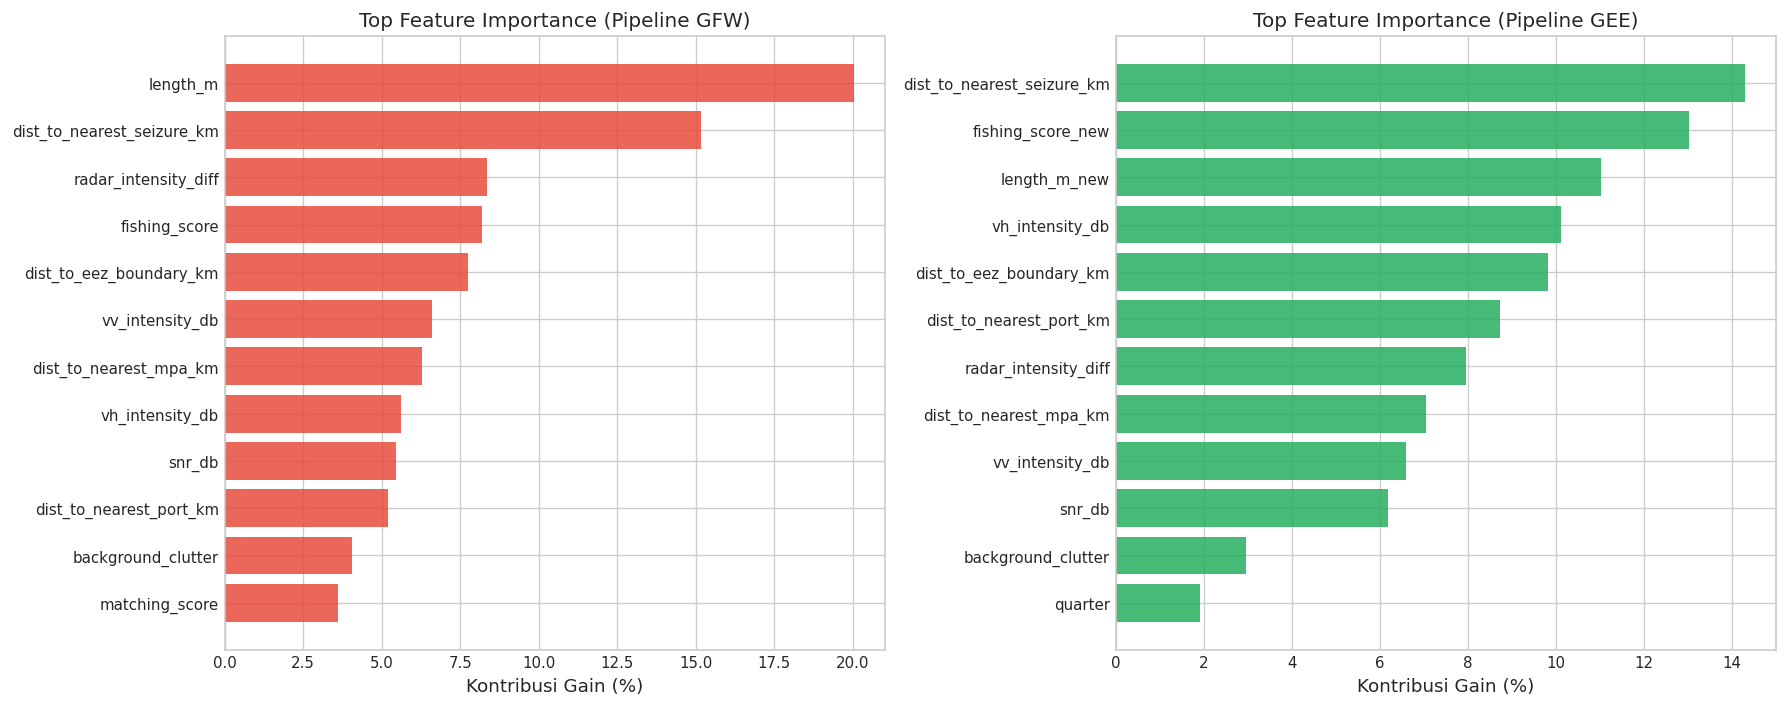

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top12_old = imp_old.head(12)
axes[0].barh(top12_old['feature'][::-1], top12_old['gain_pct'][::-1], color=PALETTE['old'], alpha=0.85)
axes[0].set_xlabel('Kontribusi Gain (%)')
axes[0].set_title('Top Feature Importance (Pipeline GFW)')

top12_new = imp_new.head(12)
axes[1].barh(top12_new['feature'][::-1], top12_new['gain_pct'][::-1], color=PALETTE['new'], alpha=0.85)
axes[1].set_xlabel('Kontribusi Gain (%)')
axes[1].set_title('Top Feature Importance (Pipeline GEE)')

plt.tight_layout()
plt.show()

# Phase 4 - STEP 2: Kalibrasi Conformal Prediction & Sistem Siaga Temporal Kuartal

1. **Kalibrasi Conformal Prediction**: Menghitung ambang skor kuantil $\hat{q}$ pada $\alpha = 0.10$ dari subset *Reliable Negative* (RN) untuk memberikan jaminan statistik cakupan deteksi IUU $90\%$ dengan batas *false alarm* $\le 10\%$.
2. **Sistem Siaga Temporal Kuartal (Quarterly Temporal Alert System)**:
   - **Tingkat Siaga**:
     - `SIAGA 1 (Prioritas Verifikasi)`: peringkat 1-3 namun nanti diurutkan per kuartal (Skor risiko $\ge Q_{70}$ (Persentil ke-70 / Top 30% tertinggi pada kuartal acuan.)
     - `SIAGA 2 (Pengamatan Terarah)`: peringkat 4-6
     - `SIAGA 3 (Pemantauan Pasif)`: peringkat 7-10
   - **Protokol tanda percentil untuk siaga 1*:
     - **Tahun 2025**: Ambang kuartal dihitung dari distribusi kuartal tahun 2025 itu sendiri.
     - **Tahun 2026**: Ambang kuartal dihitung berdasarkan distribusi kuartal yang sama pada tahun sebelumnya (tahun 2025).


In [17]:
from scipy.stats import beta as beta_dist

ALPHA = 0.10

def clopper_pearson_ci(x, n, conf=0.95):
    if n == 0:
        return (np.nan, np.nan)
    a = 1 - conf
    lo = 0.0 if x == 0 else beta_dist.ppf(a / 2, x, n - x + 1)
    hi = 1.0 if x == n else beta_dist.ppf(1 - a / 2, x + 1, n - x)
    return float(lo), float(hi)

test_p_old_full  = test_df[test_df['label'] == 'P'].copy()
test_rn_old_full = test_df[test_df['label'] == 'RN'].copy()

if 'LightGBM' in best_old_name:
    prob_rn_old = poseidon_score_lgb_old(test_rn_old_full)
    prob_test_p_old = poseidon_score_lgb_old(test_p_old_full)
elif 'XGBoost' in best_old_name:
    prob_rn_old = poseidon_score_xgb_old(test_rn_old_full)
    prob_test_p_old = poseidon_score_xgb_old(test_p_old_full)
else:
    prob_rn_old = poseidon_score_old(test_rn_old_full)
    prob_test_p_old = poseidon_score_old(test_p_old_full)

n_cal_old = len(prob_rn_old)
q_level_old = np.clip(np.ceil((n_cal_old + 1) * (1 - ALPHA)) / n_cal_old, 0.0, 1.0)
q_hat_old = float(np.quantile(prob_rn_old, q_level_old))

hits_fa_old = int((prob_rn_old >= q_hat_old).sum())
fa_rn_old = hits_fa_old / n_cal_old

n_p_old = len(prob_test_p_old)
hits_p_old = int((prob_test_p_old >= q_hat_old).sum())
cov_eval_old = hits_p_old / n_p_old if n_p_old > 0 else np.nan
cov_eval_old_lo, cov_eval_old_hi = clopper_pearson_ci(hits_p_old, n_p_old)

print(f"[Lama] Threshold dikalibrasi dari RN (n={n_cal_old}), target false alarm <= {ALPHA*100:.0f}%")
print(f"[Lama] False Alarm RN: {hits_fa_old}/{n_cal_old} ({fa_rn_old*100:.1f}%)")
print(f"[Lama] Deskriptif P 2026: {hits_p_old}/{n_p_old} tertangkap (95% CI: {cov_eval_old_lo*100:.1f}% - {cov_eval_old_hi*100:.1f}%)")

[Lama] Threshold dikalibrasi dari RN (n=4106), target false alarm <= 10%
[Lama] False Alarm RN: 409/4106 (10.0%)
[Lama] Deskriptif P 2026: 8/8 tertangkap (95% CI: 63.1% - 100.0%)


### Kalibrasi Conformal Prediction Pipeline GEE

In [18]:
test_p_new_full  = test_df_new[test_df_new['label'] == 'P'].copy()
test_rn_new_full = test_df_new[test_df_new['label'] == 'RN'].copy()

if 'LightGBM' in best_new_name:
    prob_rn_new = poseidon_score_lgb_new(test_rn_new_full)
    prob_test_p_new = poseidon_score_lgb_new(test_p_new_full)
elif 'XGBoost' in best_new_name:
    prob_rn_new = poseidon_score_xgb_new(test_rn_new_full)
    prob_test_p_new = poseidon_score_xgb_new(test_p_new_full)
else:
    prob_rn_new = poseidon_score_new(test_rn_new_full)
    prob_test_p_new = poseidon_score_new(test_p_new_full)

n_cal_new = len(prob_rn_new)
q_level_new = np.clip(np.ceil((n_cal_new + 1) * (1 - ALPHA)) / n_cal_new, 0.0, 1.0)
q_hat_new = float(np.quantile(prob_rn_new, q_level_new))

hits_fa_new = int((prob_rn_new >= q_hat_new).sum())
fa_rn_new = hits_fa_new / n_cal_new

n_p_new = len(prob_test_p_new)
hits_p_new = int((prob_test_p_new >= q_hat_new).sum())
cov_eval_new = hits_p_new / n_p_new if n_p_new > 0 else np.nan
cov_eval_new_lo, cov_eval_new_hi = clopper_pearson_ci(hits_p_new, n_p_new)

print(f"[Baru] Threshold dikalibrasi dari RN (n={n_cal_new}), target false alarm <= {ALPHA*100:.0f}%")
print(f"[Baru] False Alarm RN: {hits_fa_new}/{n_cal_new} ({fa_rn_new*100:.1f}%)")
print(f"[Baru] Deskriptif P 2026: {hits_p_new}/{n_p_new} tertangkap (95% CI: {cov_eval_new_lo*100:.1f}% - {cov_eval_new_hi*100:.1f}%)")

[Baru] Threshold dikalibrasi dari RN (n=4106), target false alarm <= 10%
[Baru] False Alarm RN: 409/4106 (10.0%)
[Baru] Deskriptif P 2026: 6/8 tertangkap (95% CI: 34.9% - 96.8%)


### Visualisasi Verifikasi Coverage Empiris vs False Alarm RN

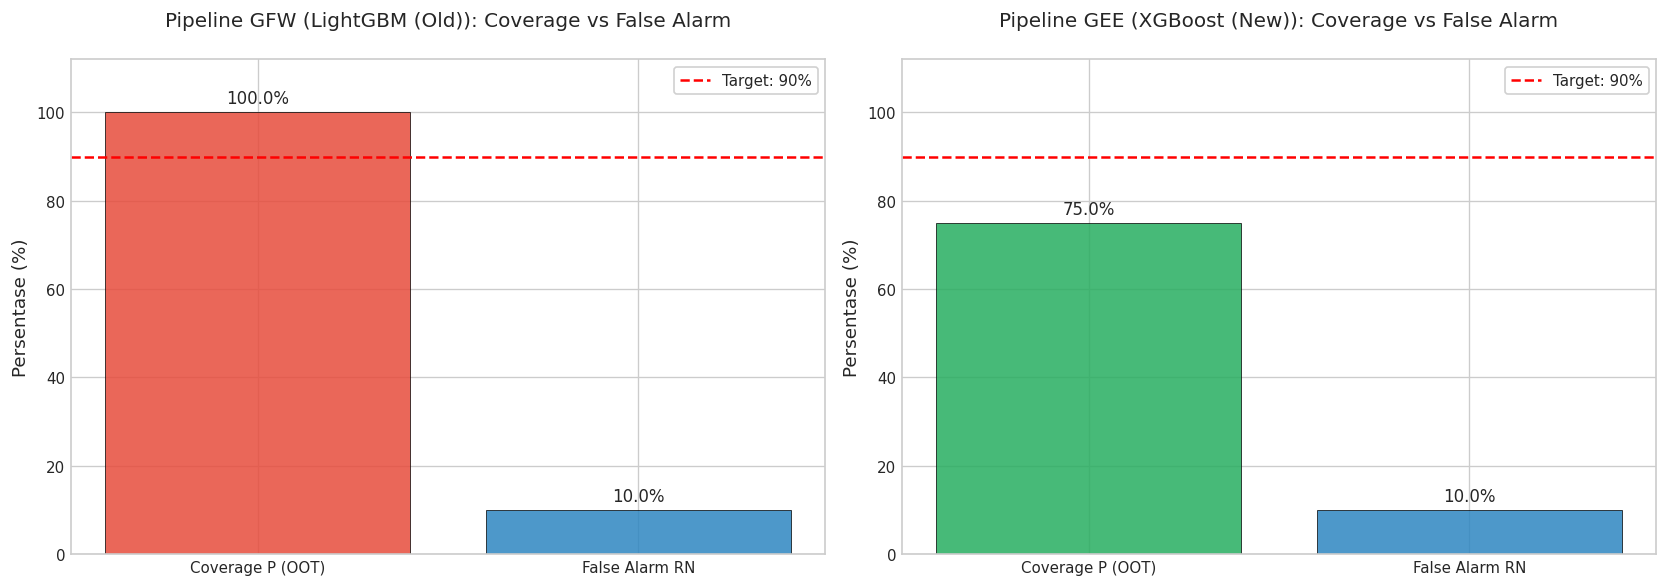

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars0 = axes[0].bar(['Coverage P (OOT)', 'False Alarm RN'], [cov_eval_old*100, fa_rn_old*100], color=[PALETTE['old'], PALETTE['rn']], alpha=0.85, edgecolor='black', linewidth=0.5)
axes[0].axhline(y=(1 - ALPHA)*100, color='red', linestyle='--', label=f'Target: {(1-ALPHA)*100:.0f}%')
axes[0].set_ylabel('Persentase (%)')
axes[0].set_title(f'Pipeline GFW ({best_old_name}): Coverage vs False Alarm', pad=20)
axes[0].set_ylim(0, 112)
axes[0].set_yticks(range(0, 101, 20))
axes[0].bar_label(bars0, fmt='%.1f%%', padding=3)
axes[0].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

bars1 = axes[1].bar(['Coverage P (OOT)', 'False Alarm RN'], [cov_eval_new*100, fa_rn_new*100], color=[PALETTE['new'], PALETTE['rn']], alpha=0.85, edgecolor='black', linewidth=0.5)
axes[1].axhline(y=(1 - ALPHA)*100, color='red', linestyle='--', label=f'Target: {(1-ALPHA)*100:.0f}%')
axes[1].set_ylabel('Persentase (%)')
axes[1].set_title(f'Pipeline GEE ({best_new_name}): Coverage vs False Alarm', pad=20)
axes[1].set_ylim(0, 112)
axes[1].set_yticks(range(0, 101, 20))
axes[1].bar_label(bars1, fmt='%.1f%%', padding=3)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### Fungsi Penentuan Ambang Siaga Temporal Kuartal

In [20]:
def compute_quarterly_alert_thresholds(df_ref, score_col='risk_score', q_col='quarter', pass_col='pass_date'):
    df_temp = df_ref.copy()
    df_temp['rank_siklus_temp'] = df_temp.groupby(pass_col)[score_col].rank(ascending=False, method='first').astype(int)

    df_siaga1_only = df_temp[df_temp['rank_siklus_temp'].isin([1, 2, 3])]

    thresholds = {}
    for q in [1, 2, 3, 4]:
        sub = df_siaga1_only[df_siaga1_only[q_col] == q]
        if len(sub) > 0 and sub[score_col].notna().sum() > 0:
            vals = sub[score_col].dropna().values
            q70 = float(np.percentile(vals, 70))
        else:
            vals_all = df_siaga1_only[score_col].dropna().values
            q70 = float(np.percentile(vals_all, 70)) if len(vals_all) > 0 else 0.001
        thresholds[q] = {'q70': q70}
    return thresholds


def assign_cycle_status_siaga(df_target, thresholds_by_q, score_col='risk_score', q_col='quarter', pass_col='pass_date'):
    df = df_target.copy()

    if pass_col not in df.columns or df[pass_col].isnull().all():
        df[pass_col] = pd.to_datetime(df['timestamp']).dt.date

    rank_series = df.groupby(pass_col)[score_col].rank(ascending=False, method='first').astype(int)
    df['rank_siklus'] = rank_series

    status_list = []
    for idx, row in df.iterrows():
        rank = row['rank_siklus']
        q_val = row[q_col] if q_col in row and pd.notna(row[q_col]) else 1
        q_val = int(q_val)
        thr = thresholds_by_q.get(q_val, thresholds_by_q.get(1, {'q70': 0.0}))
        sc = float(row[score_col]) if pd.notna(row[score_col]) else 0.0

        if rank in [1, 2, 3]:
            if sc >= thr['q70']:
                status_list.append("SIAGA 1 (Prioritas)")
            else:
                status_list.append("SIAGA 1")
        elif rank in [4, 5, 6]:
            status_list.append("SIAGA 2")
        elif rank in [7, 8, 9, 10]:
            status_list.append("SIAGA 3")
        else:
            status_list.append("SIAGA 3 (Pasif)")

    return status_list, rank_series

print("Fungsi penentuan status siaga & prioritas percentil 70 (khusus populasi Siaga 1) berhasil didefinisikan ulang.")

Fungsi penentuan status siaga & prioritas percentil 70 (khusus populasi Siaga 1) berhasil didefinisikan ulang.


# Phase 4 - STEP 3: Evaluasi Komparatif Dual Pipeline & Scoring Out-of-Time

Perbandingan 6 model komponen dan eksekusi **protokol scoring bebas data leakage**:
1. **Scoring 2025 (OOT 2025)**: Model dilatih pada data $\le 2024$, diskor pada data 2025. Ambang siaga dihitung berdasarkan distribusi tiap kuartal tahun 2025 sendiri.
2. **Scoring 2026 Januari-Juni (OOT 2026)**: Model dilatih pada data $\le 2025$, diskor pada data 2026. Ambang siaga dihitung berdasarkan distribusi kuartal yang sama pada tahun sebelumnya (tahun 2025).
3. **Scoring 2026 juli-seterusnya (OOT 2026)**: Model dilatih pada data $\le 2025$, diskor pada data 2026. Ambang siaga dihitung berdasarkan distribusi kuartal yang sama pada tahun sebelumnya (tahun 2025). namun ini pakai skema GEE, yakni hanya 13 fitur saja, dan pakai lenght_m_new dan fishing_Score_new
4. Ekstraksi daftar prioritas **Top-10 kapal terduga per siklus citra satelit** lengkap dengan `status_siaga` Kuartal.

In [21]:
all_metrics = [
    metrics_lgb_old, metrics_xgb_old, metrics_ens_old,
    metrics_lgb_new, metrics_xgb_new, metrics_ens_new,
]
df_all_compare = pd.DataFrame(all_metrics)
cols_display = ['label', 'auc_roc', 'auprc']

print("TABEL EVALUASI KOMPARATIF 6 MODEL (Pipeline GFW vs Pipeline GEE):")
print(df_all_compare[cols_display].to_string(index=False))

TABEL EVALUASI KOMPARATIF 6 MODEL (Pipeline GFW vs Pipeline GEE):
                label  auc_roc    auprc
       LightGBM (Old) 0.949489 0.005229
        XGBoost (Old) 0.942435 0.005107
Hybrid Stacking (Old) 0.946512 0.005115
       LightGBM (New) 0.923255 0.003724
        XGBoost (New) 0.926117 0.004466
Hybrid Stacking (New) 0.926145 0.004208


### Ringkasan Model Terbaik Masing-Masing Pipeline

In [22]:
delta_auprc = ((best_new_row['auprc'] - best_old_row['auprc']) / best_old_row['auprc']) * 100.0
delta_auc = ((best_new_row['auc_roc'] - best_old_row['auc_roc']) / best_old_row['auc_roc']) * 100.0

print("RINGKASAN MODEL TERBAIK TIAP PIPELINE (OOT 2023-2025 -> 2026)")
print(f"\n1. Pipeline GFW : {best_old_name}")
print(f"   AUC-ROC={best_old_row['auc_roc']:.4f} | AUPRC={best_old_row['auprc']:.6f} | Alert Efficiency={best_old_row['alert_efficiency_ratio']} = {best_old_row['alert_efficiency']:.1f}%")
print(f"\n2. Pipeline GEE : {best_new_name}")
print(f"   AUC-ROC={best_new_row['auc_roc']:.4f} | AUPRC={best_new_row['auprc']:.6f} | Alert Efficiency={best_new_row['alert_efficiency_ratio']} = {best_new_row['alert_efficiency']:.1f}%")
print(f"\nDelta AUPRC   : {delta_auprc:+.2f}%")
print(f"Delta AUC-ROC : {delta_auc:+.2f}%")

RINGKASAN MODEL TERBAIK TIAP PIPELINE (OOT 2023-2025 -> 2026)

1. Pipeline GFW : LightGBM (Old)
   AUC-ROC=0.9495 | AUPRC=0.005229 | Alert Efficiency=3/8 = 37.5%

2. Pipeline GEE : XGBoost (New)
   AUC-ROC=0.9261 | AUPRC=0.004466 | Alert Efficiency=2/8 = 25.0%

Delta AUPRC   : -14.58%
Delta AUC-ROC : -2.46%


### Visualisasi Komparatif Kurva Precision-Recall & ROC Curves

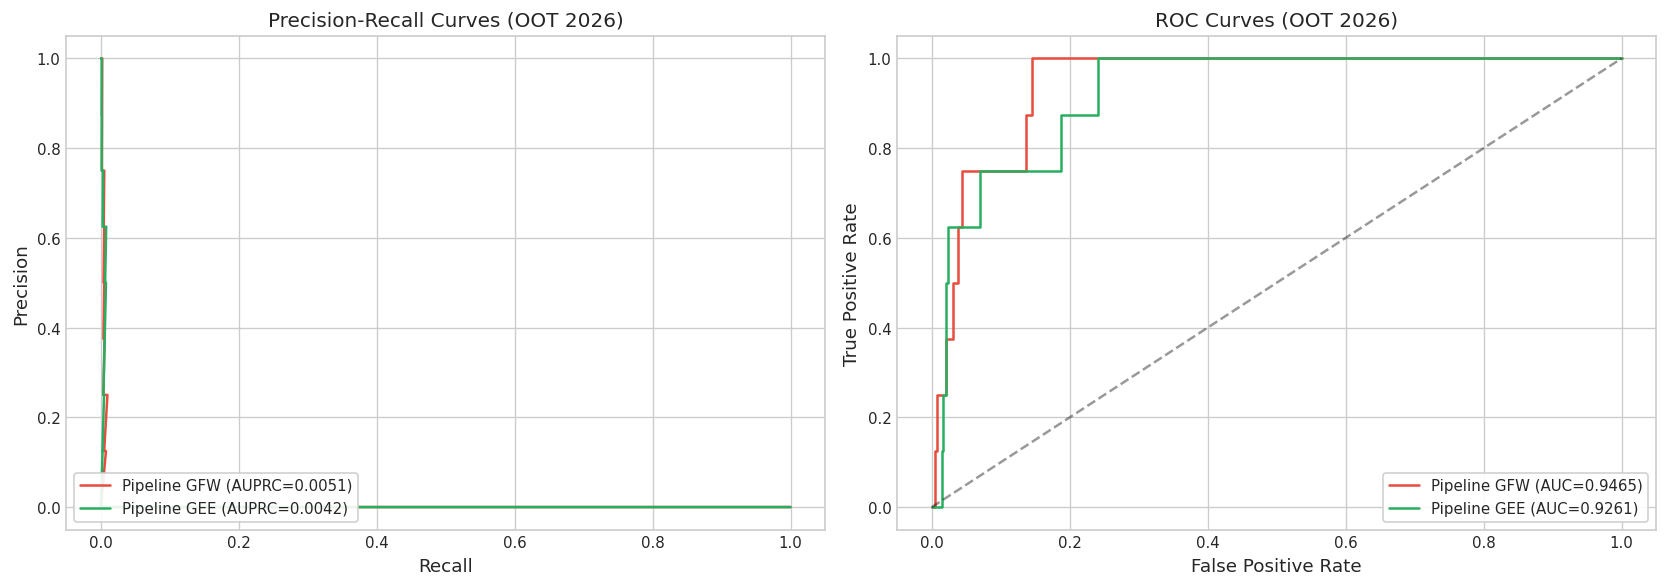

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

recalls_o, precs_o, _ = precision_recall_curve(y_test, pred_ens_old)
recalls_n, precs_n, _ = precision_recall_curve(y_test_new, pred_ens_new)
axes[0].plot(recalls_o, precs_o, color=PALETTE['old'], label=f'Pipeline GFW (AUPRC={metrics_ens_old["auprc"]:.4f})')
axes[0].plot(recalls_n, precs_n, color=PALETTE['new'], label=f'Pipeline GEE (AUPRC={metrics_ens_new["auprc"]:.4f})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curves (OOT 2026)')
axes[0].legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9)

fpr_o, tpr_o, _ = roc_curve(y_test, pred_ens_old)
fpr_n, tpr_n, _ = roc_curve(y_test_new, pred_ens_new)
axes[1].plot(fpr_o, tpr_o, color=PALETTE['old'], label=f'Pipeline GFW (AUC={metrics_ens_old["auc_roc"]:.4f})')
axes[1].plot(fpr_n, tpr_n, color=PALETTE['new'], label=f'Pipeline GEE (AUC={metrics_ens_new["auc_roc"]:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves (OOT 2026)')
axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### Evaluasi Komparatif terhadap 4 Baseline Model (Out-of-Time 2026)

Porting dan evaluasi 4 model baseline dari legacy Phase 4 pada dataset Out-of-Time (OOT 2026):
1. **Naive AIS Detection**: Kapal tanpa sinyal AIS dianggap paling mencurigakan.
2. **GFW Fishing Score Only**: Menggunakan `fishing_score` dari Global Fishing Watch sebagai satu-satunya sinyal indikator IUU.
3. **Supervised LightGBM (No PU)**: Model LightGBM supervised standar tanpa koreksi nnPU (memperlakukan seluruh data U sebagai negatif murni).
4. **AIS+SAR Stacking**: Stacking LightGBM + XGBoost pada fitur tabular AIS+SAR tanpa mempertimbangkan konteks domain spatio-temporal (seizure distance, MPA, WPP, dll).

In [24]:
pos_weight_sup = (len(train_df) - y_train.sum()) / (y_train.sum() * 5.0)

score_naive_oot = (1.0 - test_df["ais_matched"].values.astype(np.float64)) if "ais_matched" in test_df.columns else test_df["is_dark"].values.astype(np.float64)
score_naive_oot = score_naive_oot + np.random.RandomState(42).uniform(0, 0.01, size=len(score_naive_oot))

score_gfw_oot = np.nan_to_num(test_df["fishing_score"].values.astype(np.float64), nan=0.0)

oof_supervised_oot = np.zeros(len(X_test), dtype=np.float64)
for seed in SEEDS:
    sup_params = LGB_PARAMS.copy()
    sup_params.update({
        "seed": seed,
        "objective": "binary",
        "scale_pos_weight": pos_weight_sup,
        "monotone_constraints": mono_constraints_old
    })
    m_sup = lgb.train(
        sup_params,
        lgb.Dataset(X_train, label=y_train, categorical_feature=CATEGORICAL_FEATURES),
        num_boost_round=N_ROUNDS
    )
    oof_supervised_oot += m_sup.predict(X_test) / len(SEEDS)

liang_features = ["vv_intensity_db", "vh_intensity_db", "radar_intensity_diff", "snr_db", "length_m",
                  "fishing_score", "matching_score", "ais_flag_country_encoded"]
liang_cols = [c for c in liang_features if c in X_train.columns]

oof_liang_oot = np.zeros(len(X_test), dtype=np.float64)
for seed in SEEDS:
    X_tr_l, X_test_l = X_train[liang_cols], X_test[liang_cols]
    m1_l = lgb.train(
        {"objective": "binary", "scale_pos_weight": pos_weight_sup, "num_leaves": 31,
         "learning_rate": 0.05, "verbosity": -1, "seed": seed},
        lgb.Dataset(X_tr_l, label=y_train), num_boost_round=N_ROUNDS
    )
    m2_l = xgb.train(
        {"max_depth": 5, "eta": 0.05, "scale_pos_weight": pos_weight_sup,
         "objective": "binary:logistic", "seed": seed, "verbosity": 0},
        xgb.DMatrix(X_tr_l, label=y_train), num_boost_round=N_ROUNDS
    )
    oof_liang_oot += (0.5 * m1_l.predict(X_test_l) + 0.5 * m2_l.predict(xgb.DMatrix(X_test_l))) / len(SEEDS)

if 'LightGBM' in best_old_name:
    pred_poseidon_oot = pred_lgb_old
elif 'XGBoost' in best_old_name:
    pred_poseidon_oot = pred_xgb_old
else:
    pred_poseidon_oot = pred_ens_old

metrics_naive = compute_metrics(y_test, score_naive_oot, label="Naive AIS Detection")
metrics_gfw = compute_metrics(y_test, score_gfw_oot, label="GFW Fishing Score Only")
metrics_sup = compute_metrics(y_test, oof_supervised_oot, label="Supervised LightGBM (No PU)")
metrics_stacking = compute_metrics(y_test, oof_liang_oot, label="AIS+SAR Stacking")
metrics_poseidon = compute_metrics(y_test, pred_poseidon_oot, label=f"POSEIDON ({best_old_name})")

score_map_baseline = {
    'Naive AIS Detection': (metrics_naive, score_naive_oot),
    'GFW Fishing Score Only': (metrics_gfw, score_gfw_oot),
    'Supervised LightGBM (No PU)': (metrics_sup, oof_supervised_oot),
    'AIS+SAR Stacking': (metrics_stacking, oof_liang_oot),
    f"POSEIDON ({best_old_name})": (metrics_poseidon, pred_poseidon_oot)
}

for _mdict, _score in score_map_baseline.values():
    _ae = compute_alert_efficiency(test_df, _score, pass_date_col='pass_date', pu_col='pu_flag', top_n=10)
    _mdict.update(_ae)

KOLOM_RINGKAS = ['label', 'auc_roc', 'auprc', 'alert_efficiency', 'alert_efficiency_ratio']

df_baseline_compare = pd.DataFrame([
    metrics_naive, metrics_gfw, metrics_sup, metrics_stacking, metrics_poseidon
])

print("TABEL EVALUASI KOMPARATIF 4 BASELINE VS POSEIDON (OOT 2026):")
print(df_baseline_compare[KOLOM_RINGKAS].to_string(index=False))

TABEL EVALUASI KOMPARATIF 4 BASELINE VS POSEIDON (OOT 2026):
                      label  auc_roc    auprc  alert_efficiency alert_efficiency_ratio
        Naive AIS Detection 0.755427 0.000811              12.5                    1/8
     GFW Fishing Score Only 0.892619 0.001703              37.5                    3/8
Supervised LightGBM (No PU) 0.838551 0.002833               0.0                    0/8
           AIS+SAR Stacking 0.809109 0.000835               0.0                    0/8
  POSEIDON (LightGBM (Old)) 0.949489 0.005229              37.5                    3/8


## 2025 Scoring Bebas Data Leakage & Sistem Siaga Kuartal 2025 - Pipeline GFW

In [25]:
import gdown

SEIZURE_ID = "11nifviDBWXHzss3pdvZwmANNbFz2kSvi"
SEIZURE_PATH = "POSEIDON_WPP711_seizures_with_length.csv"

if not os.path.exists(SEIZURE_PATH):
    gdown.download(id=SEIZURE_ID, output=SEIZURE_PATH, quiet=False)

seiz = pd.read_csv(SEIZURE_PATH)
seiz['date'] = pd.to_datetime(seiz['date'], utc=True)
seiz['year'] = seiz['date'].dt.year

BBOX_LON_MIN, BBOX_LON_MAX = 102.90, 111.05
BBOX_LAT_MIN, BBOX_LAT_MAX = -4.16, 7.74

def compute_dist_to_seizure(lat_arr, lon_arr, seiz_lat, seiz_lon):
    lat_r = np.radians(lat_arr)[:, None]
    lon_r = np.radians(lon_arr)[:, None]
    seiz_lat_r = np.radians(seiz_lat)[None, :]
    seiz_lon_r = np.radians(seiz_lon)[None, :]

    dlat = seiz_lat_r - lat_r
    dlon = seiz_lon_r - lon_r
    a = np.sin(dlat/2)**2 + np.cos(lat_r)*np.cos(seiz_lat_r)*np.sin(dlon/2)**2
    dists_matrix = 2 * 6371.0088 * np.arcsin(np.sqrt(a))

    dists_sorted = np.sort(dists_matrix, axis=1)
    min_dists = np.where(
        dists_sorted[:, 0] < 0.05,
        np.where(dists_sorted.shape[1] > 1, dists_sorted[:, 1], -1.0),
        dists_sorted[:, 0]
    )
    return np.round(min_dists, 4)

print(f"Total seizure termuat: {len(seiz)}, kolom: {seiz.columns.tolist()}")

Total seizure termuat: 61, kolom: ['date', 'lat', 'lon', 'vessel_flag', 'vessel_type', 'gt', 'violation_note', 'source_url', 'length', 'length_lower', 'length_upper', 'year']


In [26]:
seiz_ref_2024 = seiz[(seiz['year'] <= 2024) &
                      seiz['lon'].between(BBOX_LON_MIN, BBOX_LON_MAX) &
                      seiz['lat'].between(BBOX_LAT_MIN, BBOX_LAT_MAX)].copy()

sar_labeled_wf24 = sar_labeled.copy()
sar_labeled_wf24['dist_to_nearest_seizure_km'] = compute_dist_to_seizure(
    sar_labeled_wf24['lat'].values, sar_labeled_wf24['lon'].values,
    seiz_ref_2024['lat'].values, seiz_ref_2024['lon'].values
)

df_train_2024 = sar_labeled_wf24[pd.to_datetime(sar_labeled_wf24['timestamp']).dt.year <= 2024].copy()
df_2025 = sar_labeled_wf24[pd.to_datetime(sar_labeled_wf24['timestamp']).dt.year == 2025].copy()

if df_train_2024.empty or df_2025.empty:
    raise ValueError("Data latihan 2024 atau data evaluasi 2025 tidak ditemukan.")

df_p_tr24 = df_train_2024[df_train_2024['label'] == 'P'].copy()
df_u_tr24 = df_train_2024[df_train_2024['label'] == 'U'].copy()
df_rn_tr24 = df_train_2024[df_train_2024['label'] == 'RN'].copy()

train_2024_old = pd.concat([df_p_tr24, df_u_tr24], ignore_index=True)
train_2024_old['pu_flag'] = np.where(train_2024_old['label'] == 'P', 1.0, 0.0)

X_train_24 = train_2024_old[FEATURE_COLS_OLD].astype(np.float32)
y_train_24 = train_2024_old['pu_flag'].values.astype(np.float32)
X_2025 = df_2025[FEATURE_COLS_OLD].astype(np.float32)

n_p24, n_rn24 = len(df_p_tr24), len(df_rn_tr24)
pi_point_24 = float(n_p24 / (n_p24 + n_rn24))

rng_24 = np.random.RandomState(42)
boot_pis_24 = []
for _ in range(N_BOOTSTRAP):
    p_idx = rng_24.choice(df_p_tr24.index, size=n_p24, replace=True)
    rn_idx = rng_24.choice(df_rn_tr24.index, size=n_rn24, replace=True)
    boot_pis_24.append(len(np.unique(p_idx)) / (len(np.unique(p_idx)) + len(np.unique(rn_idx))))
pi_low_24, pi_high_24 = np.percentile(boot_pis_24, [2.5, 97.5])
PI_ENSEMBLE_24 = [pi_low_24, pi_point_24, pi_high_24]
print(f"PI_ENSEMBLE_24 (GFW, 2023-2024): {PI_ENSEMBLE_24}")

pred_lgb_pi_24 = {pi_val: np.zeros(len(X_2025), dtype=np.float64) for pi_val in PI_ENSEMBLE_24}
pred_xgb_pi_24 = {pi_val: np.zeros(len(X_2025), dtype=np.float64) for pi_val in PI_ENSEMBLE_24}
dm_2025 = xgb.DMatrix(X_2025)

for seed in SEEDS:
    dtrain_24 = lgb.Dataset(X_train_24, label=y_train_24, categorical_feature=CATEGORICAL_FEATURES)
    dm_train_24 = xgb.DMatrix(X_train_24, label=y_train_24)

    for pi_val in PI_ENSEMBLE_24:
        fold_params = LGB_PARAMS.copy()
        fold_params['seed'] = seed
        fold_params['monotone_constraints'] = mono_constraints_old
        fold_params['objective'] = make_nnpu_objective(pi_val)
        model_lgb = lgb.train(params=fold_params, train_set=dtrain_24, num_boost_round=N_ROUNDS)
        pred_lgb_pi_24[pi_val] += _sigmoid(model_lgb.predict(X_2025, raw_score=True)) / len(SEEDS)

        xgb_params = XGB_PARAMS.copy()
        xgb_params['seed'] = seed
        booster = xgb.train(params=xgb_params, dtrain=dm_train_24, num_boost_round=N_ROUNDS,
                             obj=make_nnpu_objective(pi_val))
        pred_xgb_pi_24[pi_val] += _sigmoid(booster.predict(dm_2025, output_margin=True)) / len(SEEDS)

    print(f"Seed {seed} (Kalibrasi 2025, GFW) selesai.")

pred_lgb_2025 = np.mean([pred_lgb_pi_24[pi_val] for pi_val in PI_ENSEMBLE_24], axis=0)
pred_xgb_2025 = np.mean([pred_xgb_pi_24[pi_val] for pi_val in PI_ENSEMBLE_24], axis=0)
raw_2025_old = W_LGB * pred_lgb_2025 + (1 - W_LGB) * pred_xgb_2025

df_2025_old = df_2025.copy()
df_2025_old['risk_score'] = raw_2025_old
df_2025_old['pass_date'] = pd.to_datetime(df_2025_old['timestamp']).dt.date
df_2025_old['quarter'] = pd.to_datetime(df_2025_old['timestamp']).dt.quarter

thresholds_siaga_2025_old = compute_quarterly_alert_thresholds(df_2025_old, score_col='risk_score', q_col='quarter')
df_2025_old['status_siaga'], df_2025_old['rank_siklus'] = assign_cycle_status_siaga(
    df_2025_old, thresholds_siaga_2025_old, score_col='risk_score', q_col='quarter', pass_col='pass_date'
)

top10_per_cycle_old_2025 = df_2025_old[df_2025_old['rank_siklus'] <= 10].sort_values(['pass_date', 'rank_siklus']).copy()

print(f"Scoring 2025 Pipeline GFW selesai: {len(df_2025_old):,} baris.")
print(f"Ambang Kuartal 2025 (Old): {thresholds_siaga_2025_old}")
print(df_2025_old['status_siaga'].value_counts())

PI_ENSEMBLE_24 (GFW, 2023-2024): [np.float64(0.001824979417040615), 0.0021230056613484303, np.float64(0.002534218282992335)]
Seed 42 (Kalibrasi 2025, GFW) selesai.
Seed 123 (Kalibrasi 2025, GFW) selesai.
Seed 999 (Kalibrasi 2025, GFW) selesai.
Seed 7 (Kalibrasi 2025, GFW) selesai.
Seed 2024 (Kalibrasi 2025, GFW) selesai.
Scoring 2025 Pipeline GFW selesai: 52,116 baris.
Ambang Kuartal 2025 (Old): {1: {'q70': 0.04324333746271676}, 2: {'q70': 0.08676943103253613}, 3: {'q70': 0.07192096973234055}, 4: {'q70': 0.06928805374505047}}
status_siaga
SIAGA 3 (Pasif)        50357
SIAGA 3                  680
SIAGA 2                  523
SIAGA 1                  389
SIAGA 1 (Prioritas)      167
Name: count, dtype: int64


## 2025 Scoring Bebas Data Leakage & Sistem Siaga Kuartal 2025 - Pipeline GEE

In [27]:
df_train_2024_new = sar_labeled_new[pd.to_datetime(sar_labeled_new['timestamp']).dt.year <= 2024].copy()
df_2025_new = sar_labeled_new[pd.to_datetime(sar_labeled_new['timestamp']).dt.year == 2025].copy()

if df_train_2024_new.empty or df_2025_new.empty:
    raise ValueError("Data latihan 2024 atau data evaluasi 2025 tidak ditemukan.")

df_p_tr24_n = df_train_2024_new[df_train_2024_new['label'] == 'P'].copy()
df_u_tr24_n = df_train_2024_new[df_train_2024_new['label'] == 'U'].copy()
df_rn_tr24_n = df_train_2024_new[df_train_2024_new['label'] == 'RN'].copy()

train_2024_new = pd.concat([df_p_tr24_n, df_u_tr24_n], ignore_index=True)
train_2024_new['pu_flag'] = np.where(train_2024_new['label'] == 'P', 1.0, 0.0)

X_train_24_n = train_2024_new[FEATURE_COLS_NEW].astype(np.float32)
y_train_24_n = train_2024_new['pu_flag'].values.astype(np.float32)
X_2025_n = df_2025_new[FEATURE_COLS_NEW].astype(np.float32)

n_p24_n, n_rn24_n = len(df_p_tr24_n), len(df_rn_tr24_n)
pi_point_24_n = float(n_p24_n / (n_p24_n + n_rn24_n)) if (n_p24_n + n_rn24_n) > 0 else 0.01

rng_24_n = np.random.RandomState(42)
boot_pis_24_n = []
for _ in range(N_BOOTSTRAP):
    p_idx = rng_24_n.choice(df_p_tr24_n.index, size=n_p24_n, replace=True)
    rn_idx = rng_24_n.choice(df_rn_tr24_n.index, size=n_rn24_n, replace=True)
    boot_pis_24_n.append(len(np.unique(p_idx)) / (len(np.unique(p_idx)) + len(np.unique(rn_idx))))
pi_low_24_n, pi_high_24_n = np.percentile(boot_pis_24_n, [2.5, 97.5])
PI_ENSEMBLE_24_N = [pi_low_24_n, pi_point_24_n, pi_high_24_n]
print(f"PI_ENSEMBLE_24_N (GEE, 2023-2024): {PI_ENSEMBLE_24_N}")

pred_lgb_pi_24n = {pi_val: np.zeros(len(X_2025_n), dtype=np.float64) for pi_val in PI_ENSEMBLE_24_N}
pred_xgb_pi_24n = {pi_val: np.zeros(len(X_2025_n), dtype=np.float64) for pi_val in PI_ENSEMBLE_24_N}
dm_2025_n = xgb.DMatrix(X_2025_n)

for seed in SEEDS:
    dtrain_24n = lgb.Dataset(X_train_24_n, label=y_train_24_n, categorical_feature=CATEGORICAL_FEATURES_NEW)
    dm_train_24n = xgb.DMatrix(X_train_24_n, label=y_train_24_n)

    for pi_val in PI_ENSEMBLE_24_N:
        fold_params = LGB_PARAMS.copy()
        fold_params['seed'] = seed
        fold_params['monotone_constraints'] = mono_constraints_new
        fold_params['objective'] = make_nnpu_objective(pi_val)
        model_lgb = lgb.train(params=fold_params, train_set=dtrain_24n, num_boost_round=N_ROUNDS)
        pred_lgb_pi_24n[pi_val] += _sigmoid(model_lgb.predict(X_2025_n, raw_score=True)) / len(SEEDS)

        xgb_params = XGB_PARAMS.copy()
        xgb_params['seed'] = seed
        booster = xgb.train(params=xgb_params, dtrain=dm_train_24n, num_boost_round=N_ROUNDS,
                             obj=make_nnpu_objective(pi_val))
        pred_xgb_pi_24n[pi_val] += _sigmoid(booster.predict(dm_2025_n, output_margin=True)) / len(SEEDS)

    print(f"Seed {seed} (Kalibrasi 2025, GEE) selesai.")

pred_lgb_2025n = np.mean([pred_lgb_pi_24n[pi_val] for pi_val in PI_ENSEMBLE_24_N], axis=0)
pred_xgb_2025n = np.mean([pred_xgb_pi_24n[pi_val] for pi_val in PI_ENSEMBLE_24_N], axis=0)
raw_2025_new = W_LGB * pred_lgb_2025n + (1 - W_LGB) * pred_xgb_2025n

df_2025_new = df_2025_new.copy()
df_2025_new['raw_risk_score'] = raw_2025_new
df_2025_new['risk_score'] = raw_2025_new
df_2025_new['pass_date'] = pd.to_datetime(df_2025_new['timestamp']).dt.date
df_2025_new['quarter'] = pd.to_datetime(df_2025_new['timestamp']).dt.quarter

thresholds_siaga_2025_new = compute_quarterly_alert_thresholds(df_2025_new, score_col='raw_risk_score', q_col='quarter')
df_2025_new['status_siaga'], df_2025_new['rank_siklus'] = assign_cycle_status_siaga(
    df_2025_new, thresholds_siaga_2025_new, score_col='raw_risk_score', q_col='quarter', pass_col='pass_date'
)

top10_per_cycle_new_2025 = df_2025_new[df_2025_new['rank_siklus'] <= 10].sort_values(['pass_date', 'rank_siklus']).copy()

print(f"Scoring 2025 Pipeline GEE selesai: {len(df_2025_new):,} baris.")
print(f"Ambang Kuartal 2025 (New): {thresholds_siaga_2025_new}")
print(df_2025_new['status_siaga'].value_counts())

PI_ENSEMBLE_24_N (GEE, 2023-2024): [np.float64(0.001824979417040615), 0.0021230056613484303, np.float64(0.002534218282992335)]
Seed 42 (Kalibrasi 2025, GEE) selesai.
Seed 123 (Kalibrasi 2025, GEE) selesai.
Seed 999 (Kalibrasi 2025, GEE) selesai.
Seed 7 (Kalibrasi 2025, GEE) selesai.
Seed 2024 (Kalibrasi 2025, GEE) selesai.
Scoring 2025 Pipeline GEE selesai: 52,116 baris.
Ambang Kuartal 2025 (New): {1: {'q70': 0.045150796053899094}, 2: {'q70': 0.07653291480281815}, 3: {'q70': 0.07172845542284215}, 4: {'q70': 0.0649700620641555}}
status_siaga
SIAGA 3 (Pasif)        50357
SIAGA 3                  680
SIAGA 2                  523
SIAGA 1                  389
SIAGA 1 (Prioritas)      167
Name: count, dtype: int64


## 2026 Scoring Bebas Data Leakage & Sistem Siaga Kuartal (Acuan Kuartal 2025) - Pipeline GFW

In [28]:
df_2026_old = test_df[pd.to_datetime(test_df['timestamp']).dt.month <= 6].copy()

if 'LightGBM' in best_old_name:
    raw_2026_old = _sigmoid(np.mean([m.predict(df_2026_old[FEATURE_COLS_OLD].astype(np.float32), raw_score=True) for m in final_models_lgb], axis=0))
elif 'XGBoost' in best_old_name:
    dm_2026_old = xgb.DMatrix(df_2026_old[FEATURE_COLS_OLD].astype(np.float32))
    raw_2026_old = _sigmoid(np.mean([m.predict(dm_2026_old, output_margin=True) for m in final_models_xgb], axis=0))
else:
    dm_2026_old = xgb.DMatrix(df_2026_old[FEATURE_COLS_OLD].astype(np.float32))
    raw_2026_old = 0.5 * _sigmoid(np.mean([m.predict(df_2026_old[FEATURE_COLS_OLD].astype(np.float32), raw_score=True) for m in final_models_lgb], axis=0)) + \
                   0.5 * _sigmoid(np.mean([m.predict(dm_2026_old, output_margin=True) for m in final_models_xgb], axis=0))

df_2026_old['risk_score'] = raw_2026_old
df_2026_old['pass_date'] = pd.to_datetime(df_2026_old['timestamp']).dt.date
df_2026_old['quarter'] = pd.to_datetime(df_2026_old['timestamp']).dt.quarter

df_2026_old['status_siaga'], df_2026_old['rank_siklus'] = assign_cycle_status_siaga(
    df_2026_old, thresholds_siaga_2025_old, score_col='risk_score', q_col='quarter', pass_col='pass_date'
)

top10_per_cycle_old_2026 = df_2026_old[df_2026_old['rank_siklus'] <= 10].sort_values(['pass_date', 'rank_siklus']).copy()

print(f"Scoring 2026 Pipeline GFW (Jan-Jun) selesai: {len(df_2026_old):,} baris.")
print("Distribusi Status Siaga 2026 (Pipeline GFW - Jan-Jun, Acuan Kuartal 2025 GFW):")
print(df_2026_old['status_siaga'].value_counts())

Scoring 2026 Pipeline GFW (Jan-Jun) selesai: 27,049 baris.
Distribusi Status Siaga 2026 (Pipeline GFW - Jan-Jun, Acuan Kuartal 2025 GFW):
status_siaga
SIAGA 3 (Pasif)        26123
SIAGA 3                  356
SIAGA 2                  274
SIAGA 1                  271
SIAGA 1 (Prioritas)       25
Name: count, dtype: int64


## 2026 Scoring Bebas Data Leakage & Sistem Siaga Kuartal (Acuan Kuartal 2025) - Pipeline GEE

In [29]:
df_2026_new = df_2026_clean[pd.to_datetime(df_2026_clean['timestamp']).dt.month >= 7].copy()
df_2026_new['radar_intensity_diff'] = (df_2026_new['vv_intensity_db'] - df_2026_new['vh_intensity_db']).astype(np.float32)
df_2026_new['quarter'] = pd.to_datetime(df_2026_new['timestamp']).dt.quarter
df_2026_new['pass_date'] = pd.to_datetime(df_2026_new['timestamp']).dt.date

if 'sar_labeled_2026' in locals() and 'row_id' in df_2026_new.columns:
    label_map = sar_labeled_2026.set_index('row_id')['label'].to_dict()
    df_2026_new['label'] = df_2026_new['row_id'].map(label_map).fillna('U')
    df_2026_new['pu_flag'] = np.where(df_2026_new['label'] == 'P', 1.0, 0.0)
else:
    df_2026_new['label'] = 'U'
    df_2026_new['pu_flag'] = 0.0

if 'LightGBM' in best_new_name:
    raw_2026_new = poseidon_score_lgb_new(df_2026_new)
elif 'XGBoost' in best_new_name:
    raw_2026_new = poseidon_score_xgb_new(df_2026_new)
else:
    raw_2026_new = poseidon_score_new(df_2026_new)

df_2026_new['risk_score'] = raw_2026_new

df_2026_new['status_siaga'], df_2026_new['rank_siklus'] = assign_cycle_status_siaga(
    df_2026_new, thresholds_siaga_2025_new, score_col='risk_score', q_col='quarter', pass_col='pass_date'
)

top10_per_cycle_new_2026 = df_2026_new[df_2026_new['rank_siklus'] <= 10].sort_values(['pass_date', 'rank_siklus']).copy()

print(f"Scoring 2026 Pipeline GEE (Jul-Aug) selesai: {len(df_2026_new):,} baris.")
print(f"Total kapal teridentifikasi label P: {int(df_2026_new['pu_flag'].sum())}")
print("Distribusi Status Siaga 2026 (Pipeline GEE - Jul-Aug, Acuan Kuartal 2025 GEE):")
print(df_2026_new['status_siaga'].value_counts())

Scoring 2026 Pipeline GEE (Jul-Aug) selesai: 5,348 baris.
Total kapal teridentifikasi label P: 0
Distribusi Status Siaga 2026 (Pipeline GEE - Jul-Aug, Acuan Kuartal 2025 GEE):
status_siaga
SIAGA 3 (Pasif)    5089
SIAGA 3             100
SIAGA 1              82
SIAGA 2              77
Name: count, dtype: int64


In [30]:
kolom_gabung = ['timestamp', 'lat', 'lon', 'pass_date', 'quarter', 'risk_score', 'status_siaga', 'rank_siklus', 'label']

df_2026_gabungan = pd.concat([
    df_2026_old[kolom_gabung].assign(sumber_pipeline='GFW'),
    df_2026_new[kolom_gabung].assign(sumber_pipeline='GEE')
], ignore_index=True).sort_values('pass_date')

top10_per_cycle_2026_gabungan = df_2026_gabungan[df_2026_gabungan['rank_siklus'] <= 10].sort_values(['pass_date', 'rank_siklus'])

print(f"Total baris 2026 gabungan: {len(df_2026_gabungan):,} (GFW: {(df_2026_gabungan['sumber_pipeline']=='GFW').sum()}, GEE: {(df_2026_gabungan['sumber_pipeline']=='GEE').sum()})")
print(df_2026_gabungan.groupby('sumber_pipeline')['status_siaga'].value_counts())

Total baris 2026 gabungan: 32,397 (GFW: 27049, GEE: 5348)
sumber_pipeline  status_siaga       
GEE              SIAGA 3 (Pasif)         5089
                 SIAGA 3                  100
                 SIAGA 1                   82
                 SIAGA 2                   77
GFW              SIAGA 3 (Pasif)        26123
                 SIAGA 3                  356
                 SIAGA 2                  274
                 SIAGA 1                  271
                 SIAGA 1 (Prioritas)       25
Name: count, dtype: int64


## Visualisasi Distribusi Skor Risiko Komparatif & Status Siaga Kuartal

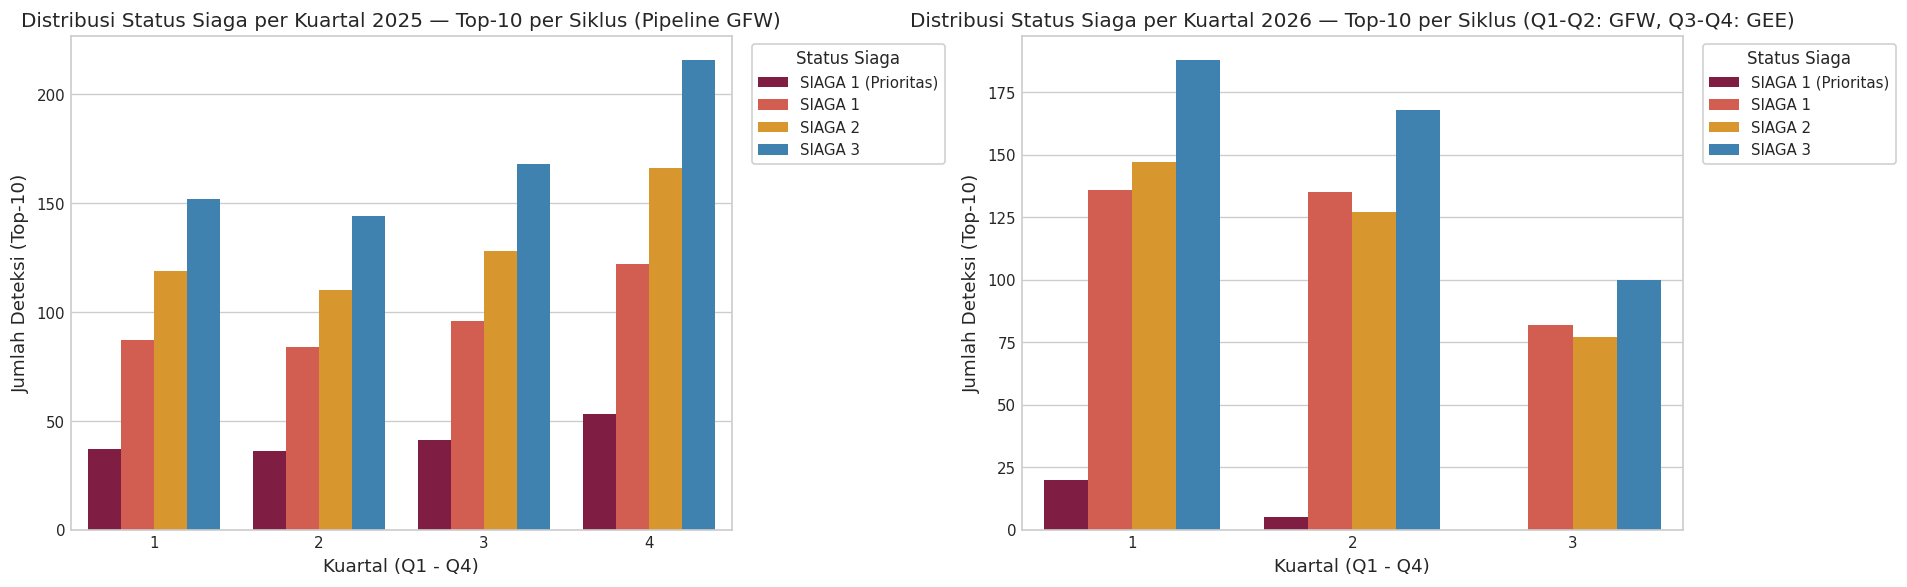

In [31]:
palette_siaga = {
    'SIAGA 1 (Prioritas)': '#900C3F',
    'SIAGA 1': '#E74C3C',
    'SIAGA 2': '#F39C12',
    'SIAGA 3': '#2E86C1',
}
order_siaga = ['SIAGA 1 (Prioritas)', 'SIAGA 1', 'SIAGA 2', 'SIAGA 3']

df_2025_top10 = df_2025_old[df_2025_old['rank_siklus'] <= 10]
df_2026_top10 = df_2026_gabungan[df_2026_gabungan['rank_siklus'] <= 10]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df_2025_top10, x='quarter', hue='status_siaga', hue_order=order_siaga, ax=axes[0], palette=palette_siaga)
axes[0].set_title('Distribusi Status Siaga per Kuartal 2025 — Top-10 per Siklus (Pipeline GFW)')
axes[0].set_xlabel('Kuartal (Q1 - Q4)')
axes[0].set_ylabel('Jumlah Deteksi (Top-10)')
axes[0].legend(title='Status Siaga', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

sns.countplot(data=df_2026_top10, x='quarter', hue='status_siaga', hue_order=order_siaga, ax=axes[1], palette=palette_siaga)
axes[1].set_title('Distribusi Status Siaga per Kuartal 2026 — Top-10 per Siklus (Q1-Q2: GFW, Q3-Q4: GEE)')
axes[1].set_xlabel('Kuartal (Q1 - Q4)')
axes[1].set_ylabel('Jumlah Deteksi (Top-10)')
axes[1].legend(title='Status Siaga', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

# Phase 4 - STEP 5: Save Hasil & Export

Penyimpanan output untuk Pipeline GFW dan Pipeline GEE:
- Skor OOF / OOT per model
- Tabel perbandingan metrik
- Risk scores 2025 & 2026 (lengkap dengan `status_siaga` Kuartal)
- Top-10 per siklus 2025 & 2026 (lengkap dengan `status_siaga` Kuartal)
- Labeled data dan metadata model terbaik
- Ekspor bobot model dan data visualisasi web

In [32]:
train_df['oof_risk_score_lgb'] = pred_lgb_old[:len(train_df)] if len(train_df) <= len(pred_lgb_old) else 0.0
train_df['oof_risk_score_xgb'] = pred_xgb_old[:len(train_df)] if len(train_df) <= len(pred_xgb_old) else 0.0
train_df['oof_risk_score_ens'] = pred_ens_old[:len(train_df)] if len(train_df) <= len(pred_ens_old) else 0.0
train_df.to_csv("poseidon_pipeline_old_oof_scores.csv", index=False)

train_df_new['oof_risk_score_lgb'] = pred_lgb_new[:len(train_df_new)] if len(train_df_new) <= len(pred_lgb_new) else 0.0
train_df_new['oof_risk_score_xgb'] = pred_xgb_new[:len(train_df_new)] if len(train_df_new) <= len(pred_xgb_new) else 0.0
train_df_new['oof_risk_score_ens'] = pred_ens_new[:len(train_df_new)] if len(train_df_new) <= len(pred_ens_new) else 0.0
train_df_new.to_csv("poseidon_pipeline_new_oof_scores.csv", index=False)

df_all_compare.to_csv("poseidon_model_comparison.csv", index=False)

df_2025_old.to_csv("poseidon_pipeline_old_2025_scores.csv", index=False)
top10_per_cycle_old_2025.to_csv("poseidon_pipeline_old_2025_top10.csv", index=False)

df_2025_new.to_csv("poseidon_pipeline_new_2025_scores.csv", index=False)
top10_per_cycle_new_2025.to_csv("poseidon_pipeline_new_2025_top10.csv", index=False)

df_2026_old.to_csv("poseidon_pipeline_old_2026_scores.csv", index=False)
top10_per_cycle_old_2026.to_csv("poseidon_pipeline_old_2026_top10.csv", index=False)

df_2026_new.to_csv("poseidon_pipeline_new_2026_scores.csv", index=False)
top10_per_cycle_new_2026.to_csv("poseidon_pipeline_new_2026_top10.csv", index=False)

sar_labeled_full.to_csv("sar_labeled_full.csv", index=False)
print("Seluruh berkas CSV berhasil diekspor.")

Seluruh berkas CSV berhasil diekspor.


### Penyimpanan Bobot Model Terlatih (LightGBM, XGBoost, Joblib)

In [33]:
final_models_lgb[0].save_model("model_lgb_old.txt")
final_models_xgb[0].save_model("model_xgb_old.json")
final_models_lgb_new[0].save_model("model_lgb_new.txt")
final_models_xgb_new[0].save_model("model_xgb_new.json")

joblib.dump({
    'models_lgb_old': final_models_lgb,
    'models_xgb_old': final_models_xgb,
    'models_lgb_new': final_models_lgb_new,
    'models_xgb_new': final_models_xgb_new,
    'features_old': FEATURE_COLS_OLD,
    'features_new': FEATURE_COLS_NEW,
    'conformal_q_old': q_hat_old,
    'conformal_q_new': q_hat_new,
    'thresholds_siaga_2025_old': thresholds_siaga_2025_old,
    'thresholds_siaga_2025_new': thresholds_siaga_2025_new,
    'alpha': ALPHA
}, "poseidon_models.pkl")

print("Seluruh artefak model weights berhasil disimpan.")

Seluruh artefak model weights berhasil disimpan.


### Ekspor Metadata Model & Data Visualisasi Web

In [34]:
metadata = {
    "system_name": "POSEIDON IUU Detection System (WPP 711)",
    "version": "2.0-2026",
    "best_model_old": best_old_name,
    "metrics_old": best_old_row.to_dict(),
    "best_model_new": best_new_name,
    "metrics_new": best_new_row.to_dict(),
    "conformal_calibration": {
        "alpha": ALPHA,
        "target_coverage": 1.0 - ALPHA,
        "q_hat_old": q_hat_old,
        "coverage_eval_old": cov_eval_old,
        "false_alarm_rn_old": fa_rn_old,
        "q_hat_new": q_hat_new,
        "coverage_eval_new": cov_eval_new,
        "false_alarm_rn_new": fa_rn_new
    },
    "quarterly_alert_thresholds_2025_old": thresholds_siaga_2025_old,
    "quarterly_alert_thresholds_2025_new": thresholds_siaga_2025_new,
    "features_old": FEATURE_COLS_OLD,
    "features_new": FEATURE_COLS_NEW,
    "total_detections_2023_2026": len(sar_labeled_full),
    "total_detections_2025": len(df_2025),
    "total_detections_2026": len(df_2026_old),
    "status": "Production Ready"
}

with open("poseidon_model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

web_viz_data = {
    "features_old": imp_old.head(15).to_dict(orient='records'),
    "features_new": imp_new.head(15).to_dict(orient='records'),
    "comparison_metrics": df_all_compare.to_dict(orient='records'),
    "quarterly_alert_thresholds": {
        "pipeline_lama_2025": thresholds_siaga_2025_old,
        "pipeline_baru_2025": thresholds_siaga_2025_new
    },
    "summary": metadata
}

with open("poseidon_web_viz_data.json", "w") as f:
    json.dump(web_viz_data, f, indent=2)

print("Metadata JSON dan web visualization data berhasil diekspor.")

Metadata JSON dan web visualization data berhasil diekspor.


### Verifikasi Integritas Seluruh Berkas Output

In [35]:
files_expected = [
    "poseidon_pipeline_old_oof_scores.csv",
    "poseidon_pipeline_new_oof_scores.csv",
    "poseidon_model_comparison.csv",
    "poseidon_pipeline_old_2025_scores.csv",
    "poseidon_pipeline_old_2025_top10.csv",
    "poseidon_pipeline_new_2025_scores.csv",
    "poseidon_pipeline_new_2025_top10.csv",
    "poseidon_pipeline_old_2026_scores.csv",
    "poseidon_pipeline_old_2026_top10.csv",
    "poseidon_pipeline_new_2026_scores.csv",
    "poseidon_pipeline_new_2026_top10.csv",
    "sar_labeled_full.csv",
    "model_lgb_old.txt",
    "model_xgb_old.json",
    "model_lgb_new.txt",
    "model_xgb_new.json",
    "poseidon_models.pkl",
    "poseidon_model_metadata.json",
    "poseidon_web_viz_data.json"
]

print("STATUS VERIFIKASI BERKAS OUTPUT:")
for f in files_expected:
    exists = os.path.exists(f)
    print(f"  [{'OK' if exists else 'PENDING'}] {f}")

STATUS VERIFIKASI BERKAS OUTPUT:
  [OK] poseidon_pipeline_old_oof_scores.csv
  [OK] poseidon_pipeline_new_oof_scores.csv
  [OK] poseidon_model_comparison.csv
  [OK] poseidon_pipeline_old_2025_scores.csv
  [OK] poseidon_pipeline_old_2025_top10.csv
  [OK] poseidon_pipeline_new_2025_scores.csv
  [OK] poseidon_pipeline_new_2025_top10.csv
  [OK] poseidon_pipeline_old_2026_scores.csv
  [OK] poseidon_pipeline_old_2026_top10.csv
  [OK] poseidon_pipeline_new_2026_scores.csv
  [OK] poseidon_pipeline_new_2026_top10.csv
  [OK] sar_labeled_full.csv
  [OK] model_lgb_old.txt
  [OK] model_xgb_old.json
  [OK] model_lgb_new.txt
  [OK] model_xgb_new.json
  [OK] poseidon_models.pkl
  [OK] poseidon_model_metadata.json
  [OK] poseidon_web_viz_data.json


In [36]:
import os
import zipfile
from google.colab import files

files_to_zip = [
    "poseidon_pipeline_old_oof_scores.csv",
    "poseidon_pipeline_new_oof_scores.csv",
    "poseidon_model_comparison.csv",
    "poseidon_pipeline_old_2025_scores.csv",
    "poseidon_pipeline_old_2025_top10.csv",
    "poseidon_pipeline_new_2025_scores.csv",
    "poseidon_pipeline_new_2025_top10.csv",
    "poseidon_pipeline_old_2026_scores.csv",
    "poseidon_pipeline_old_2026_top10.csv",
    "poseidon_pipeline_new_2026_scores.csv",
    "poseidon_pipeline_new_2026_top10.csv",
    "sar_labeled_full.csv",
    "model_lgb_old.txt",
    "model_xgb_old.json",
    "model_lgb_new.txt",
    "model_xgb_new.json",
    "poseidon_models.pkl",
    "poseidon_model_metadata.json",
    "poseidon_web_viz_data.json",
    "POSEIDON_WPP711_fallback_2026.csv",
    "POSEIDON_2026_complete_with_estimates.csv"
]

zip_filename = "POSEIDON_WPP711_Outputs_2026.zip"

files_included = []
with zipfile.ZipFile(zip_filename, 'w', compression=zipfile.ZIP_DEFLATED) as zipf:
    for f in files_to_zip:
        if os.path.exists(f):
            zipf.write(f, arcname=f)
            files_included.append(f)
            print(f"  [TERKUMPUL] {f} ({os.path.getsize(f)/1024:.1f} KB)")
        else:
            print(f"  [DILEWATI / TIDAK DITEMUKAN] {f}")

  [TERKUMPUL] poseidon_pipeline_old_oof_scores.csv (68943.8 KB)
  [TERKUMPUL] poseidon_pipeline_new_oof_scores.csv (68943.8 KB)
  [TERKUMPUL] poseidon_model_comparison.csv (1.2 KB)
  [TERKUMPUL] poseidon_pipeline_old_2025_scores.csv (28809.8 KB)
  [TERKUMPUL] poseidon_pipeline_old_2025_top10.csv (957.4 KB)
  [TERKUMPUL] poseidon_pipeline_new_2025_scores.csv (29897.0 KB)
  [TERKUMPUL] poseidon_pipeline_new_2025_top10.csv (993.3 KB)
  [TERKUMPUL] poseidon_pipeline_old_2026_scores.csv (15502.6 KB)
  [TERKUMPUL] poseidon_pipeline_old_2026_top10.csv (521.5 KB)
  [TERKUMPUL] poseidon_pipeline_new_2026_scores.csv (2593.4 KB)
  [TERKUMPUL] poseidon_pipeline_new_2026_top10.csv (123.8 KB)
  [TERKUMPUL] sar_labeled_full.csv (95804.3 KB)
  [TERKUMPUL] model_lgb_old.txt (196.2 KB)
  [TERKUMPUL] model_xgb_old.json (269.4 KB)
  [TERKUMPUL] model_lgb_new.txt (203.5 KB)
  [TERKUMPUL] model_xgb_new.json (282.4 KB)
  [TERKUMPUL] poseidon_models.pkl (13955.5 KB)
  [TERKUMPUL] poseidon_model_metadata.json 

In [37]:
files.download(zip_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import os
import json
import joblib
import zipfile
import shutil
import gdown
import numpy as np
import pandas as pd
from google.colab import files
from sklearn.metrics import precision_recall_curve, roc_curve

bundle_dir = "poseidon_master_bundle"
shutil.rmtree(bundle_dir, ignore_errors=True)
models_dir = os.path.join(bundle_dir, "automation", "models")
spatial_dir = os.path.join(bundle_dir, "automation", "spatial")
supabase_dir = os.path.join(bundle_dir, "supabase_csv_data")
frontend_dir = os.path.join(bundle_dir, "frontend_static_json")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(spatial_dir, exist_ok=True)
os.makedirs(supabase_dir, exist_ok=True)
os.makedirs(frontend_dir, exist_ok=True)

MODEL_LEN_ID = '1IPKwME5f-TgfqE5V3f99JAwKmi4y1e8R'
MODEL_FISH_ID = '1JfJ7ww1f-zRoCF1kezwSTy7e4_1szsxy'
model_len_path = 'model_length_gb.pkl'
model_fish_path = 'model_fishing_score_xgboost.pkl'

if not os.path.exists(model_len_path):
    gdown.download(id=MODEL_LEN_ID, output=model_len_path, quiet=False)
if not os.path.exists(model_fish_path):
    gdown.download(id=MODEL_FISH_ID, output=model_fish_path, quiet=False)

best_model_length = joblib.load(model_len_path)
best_model_fishing = joblib.load(model_fish_path)

joblib.dump(best_model_length, os.path.join(models_dir, "model_length_gb.pkl"))
print(f"Disimpan: model_length_gb.pkl ({type(best_model_length).__name__})")

joblib.dump(best_model_fishing, os.path.join(models_dir, "model_fishing_score_xgboost.pkl"))
print(f"Disimpan: model_fishing_score_xgboost.pkl ({type(best_model_fishing).__name__})")

poseidon_bundle_gee = {
    'models_lgb': final_models_lgb_new,
    'models_xgb': final_models_xgb_new,
    'features': FEATURE_COLS_NEW,
    'quarterly_alert_thresholds_2025': thresholds_siaga_2025_new,
    'q_hat': float(q_hat_new),
    'w_lgb': float(W_LGB),
    'pi_point': float(pi_point_new)
}
joblib.dump(poseidon_bundle_gee, os.path.join(models_dir, "poseidon_models_gee.pkl"))
print(f"Disimpan: poseidon_models_gee.pkl ({len(final_models_lgb_new)} LightGBM, {len(final_models_xgb_new)} XGBoost)")

poseidon_bundle_gfw = {
    'models_lgb': final_models_lgb,
    'models_xgb': final_models_xgb,
    'features': FEATURE_COLS_OLD,
    'quarterly_alert_thresholds_2025': thresholds_siaga_2025_old,
    'q_hat': float(q_hat_old),
    'w_lgb': float(W_LGB),
    'pi_point': float(pi_point)
}
joblib.dump(poseidon_bundle_gfw, os.path.join(models_dir, "poseidon_models_gfw.pkl"))
print(f"Disimpan: poseidon_models_gfw.pkl ({len(final_models_lgb)} LightGBM, {len(final_models_xgb)} XGBoost)")

feature_labels_map = {
    'vv_intensity_db': 'Intensitas radar VV',
    'vh_intensity_db': 'Intensitas radar VH',
    'radar_intensity_diff': 'Selisih intensitas VV-VH',
    'background_clutter': 'Tingkat noise citra radar',
    'snr_db': 'Signal-to-noise ratio',
    'length_m': 'Panjang kapal',
    'length_m_new': 'Panjang kapal (estimasi)',
    'dist_to_nearest_mpa_km': 'Jarak ke kawasan konservasi',
    'dist_to_eez_boundary_km': 'Jarak ke batas ZEE',
    'dist_to_nearest_port_km': 'Jarak ke pelabuhan',
    'dist_to_nearest_seizure_km': 'Jarak ke lokasi Locus delicti',
    'fishing_score': 'Fishing score',
    'fishing_score_new': 'Fishing score (estimasi)',
    'matching_score': 'Skor kecocokan AIS',
    'ais_flag_country_encoded': 'Negara bendera AIS',
    'area_dark_count_30d': 'Jumlah kapal gelap 30 hari terakhir',
    'area_dark_flag': 'Flag area rawan kapal gelap',
    'historical_hotspot': 'Riwayat area rawan pelanggaran',
    'quarter': 'Kuartal musim'
}

def compute_shap_explanations(df_top10, model_lgb, feature_cols, labels_map):
    if df_top10.empty:
        return {}
    X_matrix = df_top10[feature_cols].astype(np.float32)
    tree_c = model_lgb.predict(X_matrix, pred_contrib=True)[:, :-1]
    explanations = {}
    for i, (_, row_data) in enumerate(df_top10.iterrows()):
        r_id = int(row_data['row_id'])
        r_contrib = tree_c[i]
        top_idx = np.argsort(-np.abs(r_contrib))[:3]
        item_reasons = []
        for fi in top_idx:
            fname = feature_cols[fi]
            flbl = labels_map.get(fname, fname)
            fval = float(row_data[fname])
            cval = float(r_contrib[fi])
            arah = "menaikkan risiko" if cval > 0 else "menurunkan risiko"
            item_reasons.append(f"{flbl} = {fval:.3f} ({arah}, kontribusi {cval:+.4f})")
        explanations[r_id] = " | ".join(item_reasons)
    return explanations

shap_dict_2025_gfw = compute_shap_explanations(top10_per_cycle_old_2025, final_models_lgb[0], FEATURE_COLS_OLD, feature_labels_map)
shap_dict_2026_gfw = compute_shap_explanations(top10_per_cycle_old_2026, final_models_lgb[0], FEATURE_COLS_OLD, feature_labels_map)
shap_dict_2026_gee = compute_shap_explanations(top10_per_cycle_new_2026, final_models_lgb_new[0], FEATURE_COLS_NEW, feature_labels_map)
shap_dict_all = {**shap_dict_2025_gfw, **shap_dict_2026_gfw, **shap_dict_2026_gee}

top10_ranks_2025_gfw = top10_per_cycle_old_2025.set_index('row_id')['rank_siklus'].to_dict()
top10_ranks_2026_gfw = top10_per_cycle_old_2026.set_index('row_id')['rank_siklus'].to_dict()
top10_ranks_2026_gee = top10_per_cycle_new_2026.set_index('row_id')['rank_siklus'].to_dict()
top10_ranks_all = {**top10_ranks_2025_gfw, **top10_ranks_2026_gfw, **top10_ranks_2026_gee}

df_2025_old_tagged = df_2025_old.copy(); df_2025_old_tagged['sumber_pipeline'] = 'GFW'
df_2026_old_tagged = df_2026_old.copy(); df_2026_old_tagged['sumber_pipeline'] = 'GFW'
df_2026_new_tagged = df_2026_new.copy(); df_2026_new_tagged['sumber_pipeline'] = 'GEE'

df_scoring_relevant = pd.concat([df_2025_old_tagged, df_2026_old_tagged, df_2026_new_tagged], ignore_index=True)
df_scoring_relevant['pass_date'] = pd.to_datetime(df_scoring_relevant['timestamp']).dt.strftime('%Y-%m-%d')
df_scoring_relevant['hour'] = pd.to_datetime(df_scoring_relevant['timestamp']).dt.strftime('%H:%M')
df_scoring_relevant['rank_siklus'] = df_scoring_relevant['row_id'].map(top10_ranks_all)
df_scoring_relevant['conformal_flag'] = np.where(
    df_scoring_relevant['sumber_pipeline'] == 'GFW',
    (df_scoring_relevant['risk_score'] >= q_hat_old).astype(int),
    (df_scoring_relevant['risk_score'] >= q_hat_new).astype(int)
)
df_scoring_relevant['risk_factors_shap'] = df_scoring_relevant['row_id'].map(shap_dict_all).fillna('')

if 'is_dark' not in df_scoring_relevant.columns:
    df_scoring_relevant['is_dark'] = 1
if 'ais_flag_country' not in df_scoring_relevant.columns:
    df_scoring_relevant['ais_flag_country'] = 'UNKNOWN'

supabase_cols_dict = {
    'row_id': 'id',
    'pass_date': 'pass_date',
    'timestamp': 'timestamp',
    'lat': 'lat',
    'lon': 'lon',
    'risk_score': 'risk_score',
    'status_siaga': 'status_siaga',
    'rank_siklus': 'rank_siklus',
    'conformal_flag': 'conformal_flag',
    'risk_factors_shap': 'risk_factors_shap',
    'sumber_pipeline': 'sumber_pipeline',
    'length_m_new': 'length_m_new',
    'fishing_score_new': 'fishing_score_new',
    'vv_intensity_db': 'vv_intensity_db',
    'vh_intensity_db': 'vh_intensity_db',
    'snr_db': 'snr_db',
    'dist_to_nearest_mpa_km': 'dist_to_nearest_mpa_km',
    'dist_to_eez_boundary_km': 'dist_to_eez_boundary_km',
    'dist_to_nearest_port_km': 'dist_to_nearest_port_km',
    'dist_to_nearest_seizure_km': 'dist_to_nearest_seizure_km',
    'is_dark': 'is_dark',
    'ais_flag_country': 'ais_flag_country'
}

missing_cols = [c for c in supabase_cols_dict.keys() if c not in df_scoring_relevant.columns]
if missing_cols:
    for c in missing_cols:
        df_scoring_relevant[c] = np.nan

df_supabase_vessels = df_scoring_relevant[list(supabase_cols_dict.keys())].rename(columns=supabase_cols_dict).copy()
df_supabase_vessels['pass_date'] = df_supabase_vessels['pass_date'].astype(str)
df_supabase_vessels['lat'] = df_supabase_vessels['lat'].round(5)
df_supabase_vessels['lon'] = df_supabase_vessels['lon'].round(5)
df_supabase_vessels['risk_score'] = df_supabase_vessels['risk_score'].round(6)
df_supabase_vessels['length_m_new'] = df_supabase_vessels['length_m_new'].round(1)
df_supabase_vessels['fishing_score_new'] = df_supabase_vessels['fishing_score_new'].round(3)
df_supabase_vessels['vv_intensity_db'] = df_supabase_vessels['vv_intensity_db'].round(2)
df_supabase_vessels['vh_intensity_db'] = df_supabase_vessels['vh_intensity_db'].round(2)
df_supabase_vessels['snr_db'] = df_supabase_vessels['snr_db'].round(2)
df_supabase_vessels['dist_to_nearest_mpa_km'] = df_supabase_vessels['dist_to_nearest_mpa_km'].round(1)
df_supabase_vessels['dist_to_eez_boundary_km'] = df_supabase_vessels['dist_to_eez_boundary_km'].round(1)
df_supabase_vessels['dist_to_nearest_port_km'] = df_supabase_vessels['dist_to_nearest_port_km'].round(1)
df_supabase_vessels['dist_to_nearest_seizure_km'] = df_supabase_vessels['dist_to_nearest_seizure_km'].round(1)

df_supabase_vessels.to_csv(os.path.join(supabase_dir, "supabase_vessel_detections.csv"), index=False)

df_hist_only = sar_labeled_full[sar_labeled_full['year'] < 2025].copy()
df_hist_only['sumber_pipeline'] = 'HISTORIS'
df_all_passes_data = pd.concat([df_hist_only, df_scoring_relevant], ignore_index=True)
df_all_passes_data['pass_date'] = pd.to_datetime(df_all_passes_data['timestamp']).dt.strftime('%Y-%m-%d')
df_all_passes_data['hour'] = pd.to_datetime(df_all_passes_data['timestamp']).dt.strftime('%H:%M')

passes_all_records = []
for p_seq, (p_date, p_grp) in enumerate(df_all_passes_data.groupby('pass_date')):
    has_siaga = 'status_siaga' in p_grp.columns
    s1_c = int((p_grp['status_siaga'].astype(str).str.contains('SIAGA 1', na=False)).sum()) if has_siaga else 0
    s2_c = int((p_grp['status_siaga'].astype(str).str.contains('SIAGA 2', na=False)).sum()) if has_siaga else 0
    s3_c = int((p_grp['status_siaga'].astype(str).str.contains('SIAGA 3', na=False)).sum()) if has_siaga else 0
    dark_c = int((p_grp['is_dark'] == 1).sum()) if 'is_dark' in p_grp.columns else int(len(p_grp))
    p_ts = pd.to_datetime(p_date)
    passes_all_records.append({
        'pass_date': str(p_date),
        'year': int(p_ts.year),
        'month': int(p_ts.month),
        'time': str(p_grp['hour'].iloc[0]),
        'total_detections': int(len(p_grp)),
        'siaga_1_count': s1_c,
        'siaga_2_count': s2_c,
        'siaga_3_count': s3_c,
        'dark_count': dark_c,
        'seq': p_seq + 1
    })

df_supabase_passes = pd.DataFrame(passes_all_records)
df_supabase_passes.to_csv(os.path.join(supabase_dir, "supabase_satellite_passes.csv"), index=False)

df_top10_filtered = df_supabase_vessels[df_supabase_vessels['rank_siklus'].notna()].copy()
df_top10_filtered['rank_siklus'] = df_top10_filtered['rank_siklus'].astype(int)
df_supabase_top10 = df_top10_filtered.sort_values(by=['pass_date', 'rank_siklus']).reset_index(drop=True)
df_supabase_top10.to_csv(os.path.join(supabase_dir, "supabase_top10_priorities.csv"), index=False)

sz_json_items = []
if os.path.exists(SEIZURE_PATH):
    df_sz_hist = pd.read_csv(SEIZURE_PATH)
    df_sz_hist.to_csv(os.path.join(spatial_dir, "iuu_seizure_records_2023_2025.csv"), index=False)
    for _, s_r in df_sz_hist.iterrows():
        sz_json_items.append({
            "date": str(s_r.get('date', ''))[:10],
            "lat": round(float(s_r.get('lat', 0)), 5),
            "lon": round(float(s_r.get('lon', 0)), 5),
            "flag": str(s_r.get('vessel_flag', s_r.get('flag', 'Unknown'))),
            "type": str(s_r.get('type', 'Kapal Ikan')),
            "length_m": float(s_r.get('length_m', s_r.get('length', 0))),
            "matched": int(s_r.get('matched', 1))
        })

seizure_2026_path = "Seizure_WPP711_2026_with_length_FIXED.csv"
if os.path.exists(seizure_2026_path):
    df_sz_2026 = pd.read_csv(seizure_2026_path)
    df_sz_2026.to_csv(os.path.join(spatial_dir, "iuu_seizure_records_2026.csv"), index=False)
    for _, s_r in df_sz_2026.iterrows():
        sz_json_items.append({
            "date": str(s_r.get('date', ''))[:10],
            "lat": round(float(s_r.get('lat', 0)), 5),
            "lon": round(float(s_r.get('lon', 0)), 5),
            "flag": str(s_r.get('vessel_flag', s_r.get('flag', 'Unknown'))),
            "type": str(s_r.get('type', 'Kapal Ikan')),
            "length_m": float(s_r.get('length_m', s_r.get('length', 0))),
            "matched": int(s_r.get('matched', 1))
        })

if sz_json_items:
    with open(os.path.join(frontend_dir, "seizures.json"), "w") as fp:
        json.dump({"items": sz_json_items}, fp, indent=2)

fscore_new_col = df_all_passes_data['fishing_score_new'] if 'fishing_score_new' in df_all_passes_data.columns else pd.Series(np.nan, index=df_all_passes_data.index)
fscore_old_col = df_all_passes_data['fishing_score'] if 'fishing_score' in df_all_passes_data.columns else pd.Series(np.nan, index=df_all_passes_data.index)
f_score_v = fscore_new_col.fillna(fscore_old_col).fillna(0).values

grid_lat_v = (np.floor(df_all_passes_data['lat'] / 0.25) * 0.25).values
grid_lon_v = (np.floor(df_all_passes_data['lon'] / 0.25) * 0.25).values

df_fg_b = pd.DataFrame({'glat': grid_lat_v, 'glon': grid_lon_v, 'fscore': f_score_v})
fg_rows_b = []
for (gla, glo), grp in df_fg_b.groupby(['glat', 'glon']):
    fg_rows_b.append([round(float(gla), 2), round(float(glo), 2), round(float(grp['fscore'].mean()), 3), int(len(grp))])

with open(os.path.join(frontend_dir, "fishing_grid.json"), "w") as fp:
    json.dump({"cell_size": 0.25, "rows": fg_rows_b}, fp, indent=2)
with open(os.path.join(spatial_dir, "fishing_grid.json"), "w") as fp:
    json.dump({"cell_size": 0.25, "rows": fg_rows_b}, fp, indent=2)

meta_data_export = {
    "project": "POSEIDON",
    "subtitle": "Sistem prioritisasi patroli IUU fishing berbasis citra radar satelit & oseanografi",
    "region": "WPP-711 (Laut Natuna Utara, Selat Karimata, Laut Cina Selatan)",
    "generated_at": pd.Timestamp.now(tz='UTC').isoformat(),
    "data": {
        "total_detections_history": len(df_all_passes_data),
        "date_start": str(df_all_passes_data['timestamp'].min()),
        "date_end": str(df_all_passes_data['timestamp'].max()),
        "n_passes_total": len(passes_all_records),
        "label_P": int((sar_labeled_full['label'] == 'P').sum()),
        "label_RN": int((sar_labeled_full['label'] == 'RN').sum()),
        "label_U": int((sar_labeled_full['label'] == 'U').sum()),
        "detections_scored_2025": len(df_2025_old),
        "detections_scored_2026_gfw": len(df_2026_old),
        "detections_scored_2026_gee": len(df_2026_new),
        "total_detections_scored": len(df_scoring_relevant)
    },
    "model": {
        "architecture_gfw": str(best_old_name).replace("(Old)", "(GFW)"),
        "architecture_gee": str(best_new_name).replace("(New)", "(GEE)"),
        "loss": "non-negative PU Loss (Kiryo et al., 2017)",
        "class_prior_pi_gee": float(pi_point_new),
        "pi_ensemble_gee": [float(p) for p in PI_ENSEMBLE_NEW],
        "class_prior_pi_gfw": float(pi_point),
        "pi_ensemble_gfw": [float(p) for p in PI_ENSEMBLE],
        "n_seeds": len(SEEDS),
        "n_rounds": N_ROUNDS,
        "blend_weight_lgb": float(W_LGB),
        "calibration": "Conformal Prediction (alpha=0.10, target=90%)",
        "conformal_q_gfw": float(q_hat_old),
        "conformal_q_gee": float(q_hat_new),
        "n_features_gfw": len(FEATURE_COLS_OLD),
        "n_features_gee": len(FEATURE_COLS_NEW),
        "features_gfw": FEATURE_COLS_OLD,
        "features_gee": FEATURE_COLS_NEW,
        "thresholds_siaga_2025_gfw": thresholds_siaga_2025_old,
        "thresholds_siaga_2025_gee": thresholds_siaga_2025_new
    },
    "dimensions": [
        {"code": "A", "name": "Karakteristik Fisik Radar", "features": ["vv_intensity_db", "vh_intensity_db", "radar_intensity_diff", "background_clutter", "snr_db", "length_m_new"]},
        {"code": "B", "name": "Konteks Spasial & Regulasi", "features": ["dist_to_nearest_mpa_km", "dist_to_eez_boundary_km", "dist_to_nearest_port_km", "dist_to_nearest_seizure_km"]},
        {"code": "C", "name": "Aktivitas Penangkapan Ikan Oseanografi", "features": ["fishing_score_new"]},
        {"code": "D", "name": "Konteks Spasial & Temporal", "features": ["historical_hotspot", "quarter"]}
    ],
    "feature_labels": feature_labels_map
}

with open(os.path.join(frontend_dir, "meta.json"), "w") as fp:
    json.dump(meta_data_export, fp, indent=2)

best_models_summary = {
    "gfw_pipeline_best": {
        "name": str(best_old_name).replace("(Old)", "(GFW)"),
        "auc_roc": float(best_old_row["auc_roc"]),
        "auprc": float(best_old_row["auprc"]),
        "alert_efficiency": float(best_old_row["alert_efficiency"]),
        "alert_efficiency_hits": int(best_old_row["alert_efficiency_hits"]),
        "alert_efficiency_total": int(best_old_row["alert_efficiency_total"]),
        "alert_efficiency_ratio": str(best_old_row["alert_efficiency_ratio"]),
        "alert_efficiency_display": str(best_old_row["alert_efficiency_display"])
    },
    "gee_pipeline_best": {
        "name": str(best_new_name).replace("(New)", "(GEE)"),
        "auc_roc": float(best_new_row["auc_roc"]),
        "auprc": float(best_new_row["auprc"]),
        "alert_efficiency": float(best_new_row["alert_efficiency"]),
        "alert_efficiency_hits": int(best_new_row["alert_efficiency_hits"]),
        "alert_efficiency_total": int(best_new_row["alert_efficiency_total"]),
        "alert_efficiency_ratio": str(best_new_row["alert_efficiency_ratio"]),
        "alert_efficiency_display": str(best_new_row["alert_efficiency_display"])
    },
    "delta_auprc_percent": float(delta_auprc) if "delta_auprc" in globals() else 0.0,
    "delta_auc_percent": float(delta_auc) if "delta_auc" in globals() else 0.0
}

avg_risk_score_p_vs_rn = {
    "gfw": {
        "avg_score_p": float(df_p_eval['risk_score'].mean()) if 'df_p_eval' in globals() else None,
        "avg_score_rn": float(df_rn_eval['risk_score'].mean()) if 'df_rn_eval' in globals() else None
    },
    "gee": {
        "avg_score_p": float(df_p_eval_n['risk_score'].mean()) if 'df_p_eval_n' in globals() else None,
        "avg_score_rn": float(df_rn_eval_n['risk_score'].mean()) if 'df_rn_eval_n' in globals() else None
    }
}

recalls_gee, precs_gee, _ = precision_recall_curve(y_test_new, pred_ens_new)
recalls_gfw, precs_gfw, _ = precision_recall_curve(y_test, pred_ens_old)

fpr_gee, tpr_gee, _ = roc_curve(y_test_new, pred_ens_new)
fpr_gfw, tpr_gfw, _ = roc_curve(y_test, pred_ens_old)

step_gee_pr = max(1, len(recalls_gee) // 150)
step_gfw_pr = max(1, len(recalls_gfw) // 150)
step_gee_roc = max(1, len(fpr_gee) // 150)
step_gfw_roc = max(1, len(fpr_gfw) // 150)

pr_curve_gee = [[round(float(r), 4), round(float(p), 6)] for r, p in zip(recalls_gee[::step_gee_pr], precs_gee[::step_gee_pr])]
pr_curve_gfw = [[round(float(r), 4), round(float(p), 6)] for r, p in zip(recalls_gfw[::step_gfw_pr], precs_gfw[::step_gfw_pr])]

roc_curve_gee = [[round(float(f), 4), round(float(t), 4)] for f, t in zip(fpr_gee[::step_gee_roc], tpr_gee[::step_gee_roc])]
roc_curve_gfw = [[round(float(f), 4), round(float(t), 4)] for f, t in zip(fpr_gfw[::step_gfw_roc], tpr_gfw[::step_gfw_roc])]

def standardize_model_metrics(m_dict):
    lbl = str(m_dict.get('label', m_dict.get('name', ''))).replace('(Old)', '(GFW)').replace('(New)', '(GEE)')
    auc_val = float(m_dict.get('auc_roc', m_dict.get('auc', 0.0)))
    auprc_val = float(m_dict.get('auprc', 0.0))
    p20 = float(m_dict.get('p@20', 0.0))
    p50 = float(m_dict.get('p@50', 0.0))
    p100 = float(m_dict.get('p@100', 0.0))
    lift_val = float(m_dict.get('lift@20', m_dict.get('lift@100', m_dict.get('lift', 0.0))))
    if lift_val == 0.0 and 'lift@50' in m_dict:
        lift_val = float(m_dict.get('lift@50', 0.0))
    alert_hits = int(m_dict.get('alert_efficiency_hits', 0))
    alert_total = int(m_dict.get('alert_efficiency_total', 0))
    alert_eff = float(m_dict.get('alert_efficiency', 0.0))
    alert_ratio = str(m_dict.get('alert_efficiency_ratio', f"{alert_hits}/{alert_total}"))
    alert_display = str(m_dict.get('alert_efficiency_display', f"{alert_eff:.1f}".replace('.', ',') + '%'))

    return {
        'label': lbl,
        'name': lbl,
        'auc_roc': auc_val,
        'auprc': auprc_val,
        'lift': lift_val,
        'lift@20': float(m_dict.get('lift@20', 0.0)),
        'lift@50': float(m_dict.get('lift@50', 0.0)),
        'lift@100': float(m_dict.get('lift@100', 0.0)),
        'p@20': p20,
        'p@50': p50,
        'p@100': p100,
        'alert_efficiency': alert_eff,
        'alert_efficiency_hits': alert_hits,
        'alert_efficiency_total': alert_total,
        'alert_efficiency_ratio': alert_ratio,
        'alert_efficiency_display': alert_display,
        'p_in_top1pct': int(m_dict.get('p_in_top1pct', 0))
    }

pipeline_models_raw = [
    metrics_lgb_old, metrics_xgb_old, metrics_ens_old,
    metrics_lgb_new, metrics_xgb_new, metrics_ens_new
]
baseline_models_raw = [
    metrics_naive, metrics_gfw, metrics_sup, metrics_stacking
]

all_models_standardized = [standardize_model_metrics(m) for m in (pipeline_models_raw + baseline_models_raw)]
comparison_standardized = [standardize_model_metrics(m) for m in pipeline_models_raw]
baselines_standardized = [standardize_model_metrics(m) for m in baseline_models_raw]

feature_list_gee = [{"feature": f, "label": feature_labels_map.get(f, f)} for f in FEATURE_COLS_NEW]
feature_list_gfw = [{"feature": f, "label": feature_labels_map.get(f, f)} for f in FEATURE_COLS_OLD]

imp_gee_records = imp_new.to_dict(orient="records") if 'imp_new' in globals() else []
imp_gfw_records = imp_old.to_dict(orient="records") if 'imp_old' in globals() else []

conformal_info = {
    "alpha": float(ALPHA),
    "target_coverage": float(1.0 - ALPHA),
    "gee": {
        "q_hat": float(q_hat_new),
        "coverage_eval": float(cov_eval_new),
        "false_alarm_rn": float(fa_rn_new)
    },
    "gfw": {
        "q_hat": float(q_hat_old),
        "coverage_eval": float(cov_eval_old),
        "false_alarm_rn": float(fa_rn_old)
    },
    "q_hat": float(q_hat_new),
    "coverage_eval": float(cov_eval_new),
    "false_alarm_rn": float(fa_rn_new)
}

metrics_data_export = {
    "comparison": comparison_standardized,
    "baselines_oot2026": baselines_standardized,
    "all_models": all_models_standardized,
    "best_models_two_pipelines": best_models_summary,
    "avg_risk_score_p_vs_rn": avg_risk_score_p_vs_rn,
    "poseidon": standardize_model_metrics(best_new_row.to_dict()),
    "pr_curve": pr_curve_gee,
    "pr_curve_gee": pr_curve_gee,
    "pr_curve_gfw": pr_curve_gfw,
    "roc_curve": roc_curve_gee,
    "roc_curve_gee": roc_curve_gee,
    "roc_curve_gfw": roc_curve_gfw,
    "feature_importance": imp_gee_records[:13],
    "feature_importance_gee": imp_gee_records,
    "feature_importance_gfw": imp_gfw_records,
    "feature_lists": {
        "gee": feature_list_gee,
        "gfw": feature_list_gfw
    },
    "conformal": conformal_info,
    "label_P": int((sar_labeled_full['label'] == 'P').sum()) if 'sar_labeled_full' in globals() and 'label' in sar_labeled_full.columns else 0,
    "label_RN": int((sar_labeled_full['label'] == 'RN').sum()) if 'sar_labeled_full' in globals() and 'label' in sar_labeled_full.columns else 0,
    "label_U": int((sar_labeled_full['label'] == 'U').sum()) if 'sar_labeled_full' in globals() and 'label' in sar_labeled_full.columns else 0,
    "label_counts": {
        "label_P": int((sar_labeled_full['label'] == 'P').sum()) if 'sar_labeled_full' in globals() and 'label' in sar_labeled_full.columns else 0,
        "label_RN": int((sar_labeled_full['label'] == 'RN').sum()) if 'sar_labeled_full' in globals() and 'label' in sar_labeled_full.columns else 0,
        "label_U": int((sar_labeled_full['label'] == 'U').sum()) if 'sar_labeled_full' in globals() and 'label' in sar_labeled_full.columns else 0,
        "total": len(sar_labeled_full) if 'sar_labeled_full' in globals() else 0
    }
}

with open(os.path.join(frontend_dir, "metrics.json"), "w") as fp:
    json.dump(metrics_data_export, fp, indent=2)

zip_master_output = "POSEIDON_DATA_DASHBOARD_2026.zip"
with zipfile.ZipFile(zip_master_output, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for root, _, fnames in os.walk(bundle_dir):
        for fn in fnames:
            fp = os.path.join(root, fn)
            arcname = os.path.relpath(fp, bundle_dir)
            zf.write(fp, arcname=arcname)
            print(f"Mengarsipkan: {arcname}")

print(f"Ekspor berhasil! File master: {zip_master_output} ({os.path.getsize(zip_master_output)/(1024*1024):.2f} MB)")
files.download(zip_master_output)

Disimpan: model_length_gb.pkl (GradientBoostingRegressor)
Disimpan: model_fishing_score_xgboost.pkl (XGBRegressor)
Disimpan: poseidon_models_gee.pkl (15 LightGBM, 15 XGBoost)
Disimpan: poseidon_models_gfw.pkl (15 LightGBM, 15 XGBoost)
Mengarsipkan: automation/spatial/fishing_grid.json
Mengarsipkan: automation/spatial/iuu_seizure_records_2023_2025.csv
Mengarsipkan: automation/models/model_length_gb.pkl
Mengarsipkan: automation/models/poseidon_models_gfw.pkl
Mengarsipkan: automation/models/poseidon_models_gee.pkl
Mengarsipkan: automation/models/model_fishing_score_xgboost.pkl
Mengarsipkan: frontend_static_json/seizures.json
Mengarsipkan: frontend_static_json/fishing_grid.json
Mengarsipkan: frontend_static_json/meta.json
Mengarsipkan: frontend_static_json/metrics.json
Mengarsipkan: supabase_csv_data/supabase_satellite_passes.csv
Mengarsipkan: supabase_csv_data/supabase_vessel_detections.csv
Mengarsipkan: supabase_csv_data/supabase_top10_priorities.csv
Ekspor berhasil! File master: POSEIDO

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>